# Project 2: Filter design & signal enhancement

$
\newcommand{\matcmd}[2][(\cdot)]{\texttt{#2}#1}
\renewcommand{\matcmd}[2][(\cdot)]{\mathrm{#2}#1}
\newcommand{\pyt}{\matcmd[]{Python}}
% Project 2 specific
\newcommand{\bw}{\text{BW}}
\newcommand{\fds}[2][z]{#2(#1)}
$

<big> Please first fill in your names and group number </big>

Group number: 11

member names: Sen Huybrechts, Daan Debaillie

In [1]:
from importstatements import *
%matplotlib inline
notebook_styling()
import numpy as np
from scipy.signal import freqz

<IPython.core.display.Latex object>

## Introduction

In this project we will get hands on experience with designing simple, yet effective filters. These filters can be used for signal enhancement by removing unwanted noise components from the noisy input signal. Such filters are usually standard components in practical signal capture and analysis frameworks.

Specifically, in this project, we will study the following filters:
1. The design of a notch filter for removing narrowband noise (e.g., power source hum and its harmonics is a frequently seen source of disturbance in real world recordings)
2. The implementation of a simple *adaptive* filter to remove echo in a communications signal

## Submitting the project

The deliverable for the project should only consist of this notebook and possibly some extra `.py` files if wanted. Meaning that this notebook contains both your code and your answers to the questions (with figures and tables).
The code/answer locations will be indicated, however, it is allowed to add extra cells.

The project should be uploaded in the form of a zip- or a rar-archive onto the drop box of the course. **Make sure the contents are readable to all the course evaluators and not just the lecturer-in-charge.**

Make sure your Python code is well-commented. Also Make sure that the axes of the figures are clearly labeled, and that the figures have titles. **You will get points for doing so!** Keep your answers compact but clear. You may write the answers in Dutch or English.


## Useful tools for the design of filters

Having seen the basic components of digital filters and how they can be manipulated, we shall apply this knowledge to the design of simple, yet useful filters. We know that in the $\ztrans$-domain, the transfer function $\zds{H}$ can be expressed as:

\begin{equation}
    \zds{H} = \dfrac{\zds{B}}{\zds{A}} = b_0 \zpow[M-K]\dfrac{\prod_{k}(\zpow[]-\zpow[]_{k})}{\prod_{m}(\zpow[]-p_{m})}\,.
\end{equation}

This transfer function defines the frequency response of the filter. Since this is a rational function of the polynomials $\zds{A}$ and $\zds{B}$, we shall start with defining some helper functions to efficiently compute the polynomials $\zds{A}$ and $B(z)$, given the poles $p_m$ and the zeros $z_k$ of a filter.


**Note:** for high-level scientific computing languages such as $\matcmd[]{Matlab}$ or $\matcmd[]{Python}$ a polynomial $\zds{D}$ of order $M$ is usually represented as a vector of $M+1$ components, where the components are the *coefficients* of $\zds{D}$ ordered according to *decreasing powers* of $\zpow[]$. E.g., $\zds{D} = d_0 + d_1 \zpow + d_2 \zpow[-2]$ would be represented as: `Dz = (d0 ,d1 ,d2)`


### Helper function: Polynomial multiplication

Multiplication of
$D_1(z) = d_{10} + d_{11}z^{-1} + \ldots$ $\hspace{10pt}$ and $\hspace{10pt}$
$D_2(z) = d_{20} + d_{21}z^{-1} + \ldots$  
yields the polynomial $D(z) = D_1(z)D_2(z)$ with coefficients that can be obtained by *convolving* the sequences $\{d_{10},d_{11},\ldots\}$ and $\{d_{20},d_{21},\ldots\}$. **Convince yourself that this will indeed be the case (doing this numerically, by multiplying some polynomials, would be the easiest way)!**

<div class="alert alert-info">
    
Based on the above reasoning for polynomial multiplication, write the function `polyD = PolynomialMultiply(polyA,polyB)` to return the product of any two polynomials $D_1(z)$ and $D_2(z)$, where the polynomials may each be of a *different* and *arbitrary* order. **hint:** the [`np.convolve`][conv] function might be helpful.
</div>

[conv]: https://numpy.org/doc/stable/reference/generated/numpy.convolve.html

In [2]:
def PolynomialMultiply(polyA, polyB):
    return np.convolve(polyA, polyB)

#test:

polyA = (1, 1)
polyB = (1, 1, 1j)
print(PolynomialMultiply(polyA,polyB)) #should be [1.+0.j, 2.+0.j, 1.+1.j, 0.+1.j]
print(PolynomialMultiply(polyA,polyB) == [1.+0.j, 2.+0.j, 1.+1.j, 0.+1.j])

[1.+0.j 2.+0.j 1.+1.j 0.+1.j]
[ True  True  True  True]


### Helper function: Complex pairs
When designing filters with complex poles and zeroes, we know that these poles and zeros are always accompanied by their complex conjugate if the filter has a real-valued impulse response (the case for most practical filters). 

In other (more mathematical) words, if $z-z_0$ is the root of a polynomial $D(z) = d_0 + d_1z^{-1}+d_2z^{-2}\ldots$ with $\{d_0,d_1,\ldots\}\in\mathbb{R}$, and if $z_0\in\mathbb{C}$, then $z-z_0^{\ast}$ is also a root of $D(z)$. We can group such complex pairs together to get a second-order polynomial with real-valued coefficients as $(z-z_0)(z-z_0^{\ast}) = z^2-2\text{Re}(z_0)\,z+|z_0^2|$.

<div class="alert alert-info">
    
Write a function `polyOut = GetComplexPairPoly(polyIn)` that, given a first order polynomial with a complex root, returns a resulting polynomial that is of second order, by multiplying the input polynomial with its complex conjugate. You may either explicitly write out the formula above or use your `PolynomialMultiply()` function.
</div>

In [3]:
def GetComplexPairPoly(polyIn):
    return PolynomialMultiply(polyIn, np.conjugate(polyIn))

#test:
polyIn = (1, 1/np.sqrt(2) + 1/np.sqrt(2)*1j)
print(GetComplexPairPoly(polyIn)) #should be [1.+0.j, 1.41421356+0.j, 1.+0.j]

[1.        +0.j 1.41421356+0.j 1.        +0.j]


### Helper function: plots

Underneath, some plot functions are defined. However, they are not fully completed. Completing these will boost journey through the course!
<div class="alert alert-info">
    
Complete the following functions:
1. zPlane: Also calculate the poles.
2. plotAmplitude: use the [`freqz()`][freqz] function from `scipy.signal` to get W and H. Set the parameters such that you get 2048 equally spaced frequencies in the range $f\in[0,F_s]$
</div>

You can use these functions to plot and interpret your results during the rest of the project. Also, don't hesitate to change the functions in order to illustrate your answers as clearly as possible!

[freqz]: https://docs.scipy.org/doc/scipy/reference/generated/scipy.signal.freqz.html

In [4]:
def zPlane(Bz, Az, xlim=(-1.5,1.5), ylim=(-1.5,1.5)):
    
    zeros = np.roots(Bz)
    poles = np.roots(Az)
    
    fig, ax = plt.subplots()
    ax.plot(np.real(zeros), np.imag(zeros), 'o',color='b', markersize=8)
    ax.plot(np.real(poles) , np.imag(poles) , 'x', color='r', markersize=8)
    ax.set_xlim(np.array(xlim))
    ax.set_ylim(np.array(ylim))

    ax.add_artist(plt.Circle((0, 0), 1, fill=False, color='black', linewidth= 1.5))
    ax.set_aspect('equal')
    ax.grid(True)

def plotAmplitude(Bz, Az, flim=(0, 0.5), fs=1):
    
    # add freqz() function
    W, H = freqz(Bz, Az, worN=2048, whole=True, fs=fs)
    
    fig = plt.figure()
    ax = fig.add_subplot()
    ax.plot(W,20*np.log10(np.minimum(1e4,np.maximum(1e-5,np.abs(H)))))
    
    ax.grid(True)
    ax.set_xlim(flim)
    ax.set_ylabel('Amplitude [dB]')
    if fs == 1: #normelised frequency
        ax.set_xlabel('Frequency [$fT_s$]')
    else:
        ax.set_xlabel('Frequency [$Hz$]')
    ax.set_title('Amplitude response')


def plotFilter(Bz, Az, flim=(0, 0.5), xlim=(-1.5,1.5), ylim=(-1.5,1.5), fs=1):
    
    ## plot z-plane
    zPlane(Bz, Az, xlim, ylim)
    
    ## plot amplitude
    plotAmplitude(Bz, Az, flim=flim, fs=fs)
    
    
    
# Used to plot the spectrum as a spectrogram
# uses signal x, sampling frequency fs, width of window n_window, magnitude of overlap n_overlap and frequency interval to plot flim
def plotSpectrum(x, fs, n_window=2048, n_overlap=0.5, flim=None):
    x = x.real
    f, t, Sxx = sig.spectrogram(x, fs, nperseg=n_window, noverlap=n_overlap*n_window, window = 'hann')
    
    fig = plt.figure(figsize=(15,5))
    ax = fig.add_subplot()
    ax.pcolormesh(t, f, 20*np.log10(np.minimum(1e4,np.maximum(1e-10,np.abs(Sxx)))), shading='gouraud')
    ax.set_ylabel('Frequency [Hz]')
    ax.set_xlabel('Time [sec]')
    if flim is not None:
        ax.set_ylim(flim)
    plt.show()
    
    return Sxx

## Playing around with poles and zeros

First thing we will do, is further cement our understanding of poles and zeros. We will look at how the placement of these poles and zeros affects the filter response and filter stability. Plotting these poles and zeros in the z-plane will be an useful tool!

### Z-transform

Consider the following relation between the input signal $x(n)$ and the output signal $y(n)$:

$$y(n) = 0.5\,x(n)-0.5\,x(n-2)-0.2\,y(n-1)-0.2\,y(n-2)+0.8\,y(n-3) $$

As we have seen in the lecture, this defines a filtering operation on $x(n)$. Now we will try to understand the effect of this filter. In the current version, it is not straight forward to spot what this does. For a more interpretable form, we will go to z-domain!

<div class="alert alert-info">
    
Rearrange the equation and compute the transfer function as $H(z) = \dfrac{Y(z)}{X(z)} = \dfrac{B(z)}{A(z)}$. 

</div>

<div class="alert alert-success">
Write your answer here:
    
* $B(z) = $[0.5+0.j, 0.+0.j, -0.5+0.j] (0.5 - 0.5*z**-2)
* $A(z) = $[1.+0.j, 0.2+0.j, 0.2+0.j, -0.8+0.j] (1 + 0.2*z**-1 + 0.2*z**-2 - 0.8*z**-3)
</div>

### Filter interpretation on the z-plane

<div class="alert alert-info">
    
Plot the pole-zero representation of the previous filter. You can use the provided `zPlane(Bz, Az)` function. **Hint:** make sure the order of $B(z)$ and $A(z)$ are the same
</div>

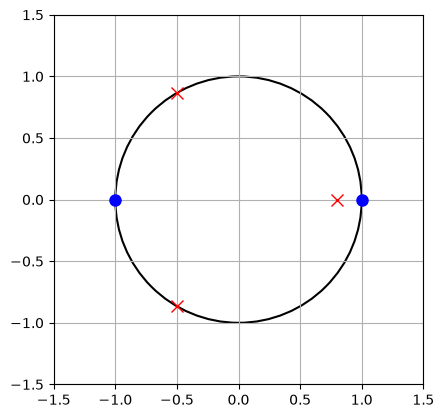

In [5]:
# Plot the pole-zero representation

Bz = (0.5, 0, -0.5)
Az = (1, 0.2, 0.2, -0.8)
zPlane(Bz, Az)

<div class="alert alert-info">
    
List your observations and conclusions regarding the filter based on these poles and zeroes. What frequencies do you expect to be boosted/attenuated? Is the filter stable? 
    
</div>

<div class="alert alert-success">
Frequencies close to poles will be boosted (H(z) is large there), and frequencies close to zeros will be attentuated (H(z) is small there).
There is a zero at z=1, so the DC component (f=Fs/2) will be completely blocked.
There is a zero at z=-1, so the very high frequencies will also be blocked.
There is a complex poles pair at z=-0.5+-sqrt(3)/2*j, with an angle of 120°. The gain here (at f = Fs/3 and 2*Fs/3) is infinite as they lie on the unit circle.
The pole at z=0.8 partially cancels out the zero at z=1.

The filter is marginally stable due to the complex pole pair on the unit circle.
</div>

<div class="alert alert-info">
    
Now also plot the frequency response of the filter. The provided `plotAmplitude(Bz, Az)` can be used.
    
</div>

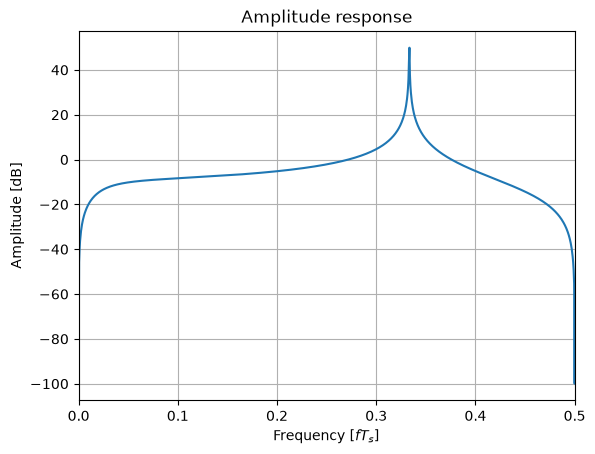

In [6]:
# plot the amplitude response

plotAmplitude(Bz, Az)

<div class="alert alert-info">
    
Do your observations on the z-plane correspond with what you see on the amplitude response? 

Indicate why (not)!
    
</div>

<div class="alert alert-success">
It does correspond with the predictions.
The amplitude does not seem to go to infinity or -infinity at f=Fs/3 and f=Fs/2 respectively due to the imprecision of the plot tool.</div>

### Moving poles and zeros around

Now we will fully focus on poles and zeros in the z-plane. We will shuffle around with them and try to understand the influence they have on the frequency response. We will start with a system with one pole and zero and then go to systems with two complex pole and zero pairs.

**First order system**

<div class="alert alert-info">

Make a system with one pole at z=0.8 and one zero at z=-1 ($p_0 = 0.8$, $z_0=-1$). Plot the z-plane and frequency response. The `plotFilter(Bz, Az)` function can be used for this.
1. What type of filter is this?
2. How can you see that in the z-plane?
    
</div>

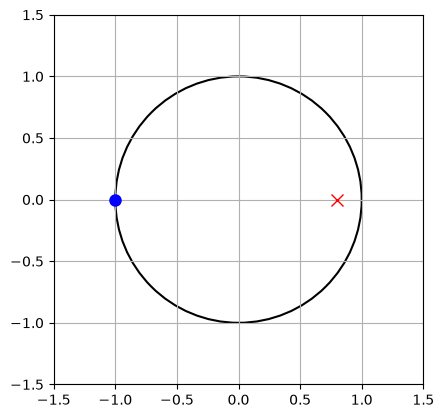

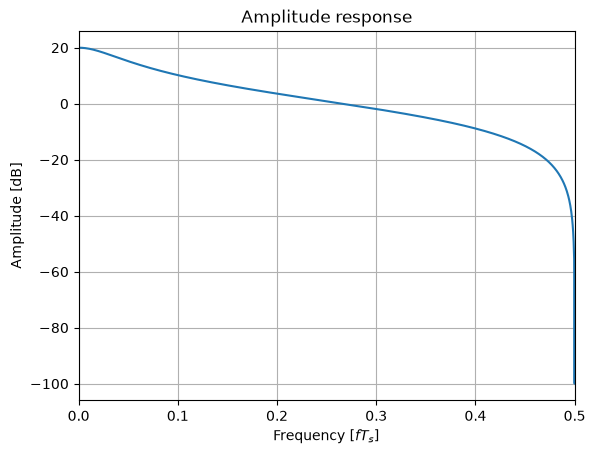

In [7]:
# Write your code for the first order system

Bz = (1, 1)
Az = (1, -0.8)

plotFilter(Bz, Az)

<div class="alert alert-success">
The pole at z=0.8 near z=1 boosts low frequencies, while the zero at z=-1 filters out f=Fs/2.
This is a sort of low pass filter, where the low frequencies are boosted with a factor 10.
</div>

**Second order system**

For these systems, we will slightly change the way the poles and zeros are written. Instead of writing a pole or zero in $z = a + bj$, we will  write it as $z =  r e^{ \jmath 2\pi F_c\tsamp}$. This makes it so the radius and angle is directly visible in the notation of the pole/zero. These might help with explaining the following scenarios. 

<div class="alert alert-info">

Make a real valued filter where one pole $p_0 = r_p e^{ \jmath \alpha_p}$ and one zero $z_0 = r_z e^{ \jmath \alpha_z}$ have the following parameters: $r_p = 0.85$, $r_z = 0.95$ and $\alpha_p = \alpha_z = \pi/6$.
1. What is the position of the second pole and zero?
2. Plot the z-plane and the amplitude response of this filter. Can you explain the behaviour of response based on the poles and zeros?
    
</div>

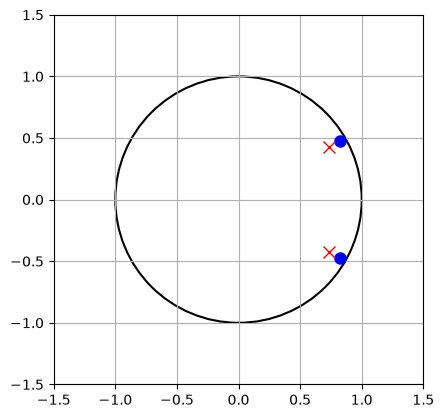

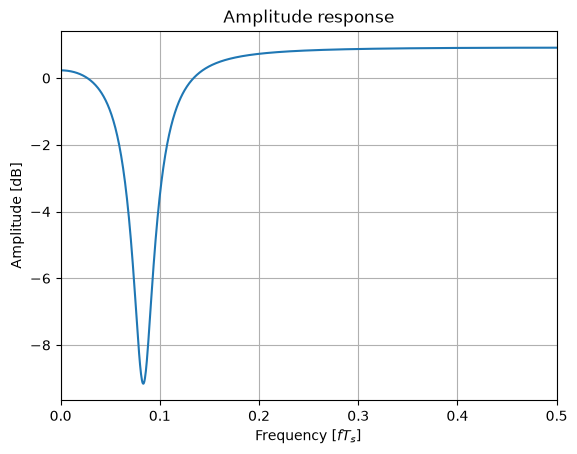

In [8]:
# Write your code here
Bz = PolynomialMultiply((-1, 0.95*np.exp(np.pi/6*1j)),(-1, 0.95*np.exp(-np.pi/6*1j)))
Az = PolynomialMultiply((-1, 0.85*np.exp(np.pi/6*1j)),(-1, 0.85*np.exp(-np.pi/6*1j)))
plotFilter(Bz, Az)

<div class="alert alert-success">
1. The second pole and zero are the complex conjugates of the first ones, so the same amplitudes, but opposite angles.
2. The presence of both poles and zeros near z=1 (but the poles are slightly closer) makes it so very low frequencies are slightly amplified, and frequencies of around Fs/12 (due to the angle being Pi/6) are filtered attenuated. Higher frequencies are boosted since the poles are closer.
</div>

<div class="alert alert-info">

Now we will change the positions of the poles and zeros. For each combination, **shortly** describe what the amplitude response looks like, and try to make the connection with the position of the poles and zeros. 

1. $r_p = 0.65$, $r_z = 0.95$ and $\alpha_p = \alpha_z = \pi/6$
2. $r_p = 0.95$, $r_z = 0.85$ and $\alpha_p = \alpha_z = \pi/6$
3. $r_p = 0.85$, $r_z = 0.95$, $\alpha_p = 5\pi/6$ and $\alpha_z = \pi/6$
    
</div>

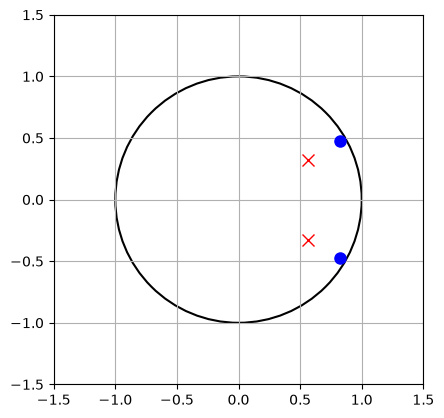

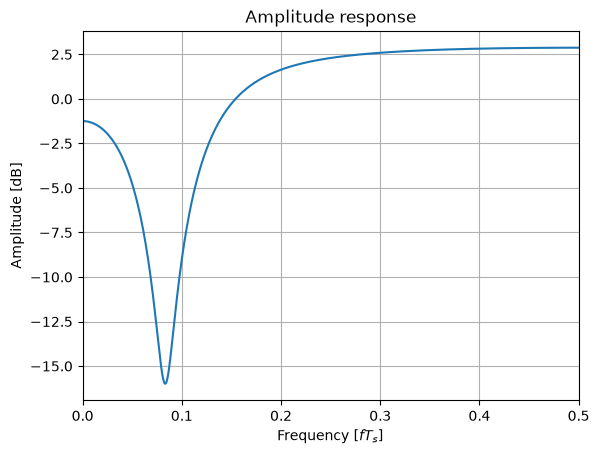

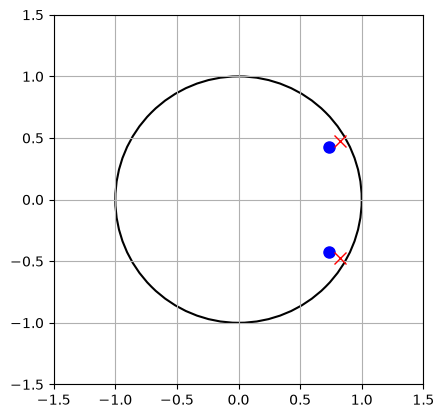

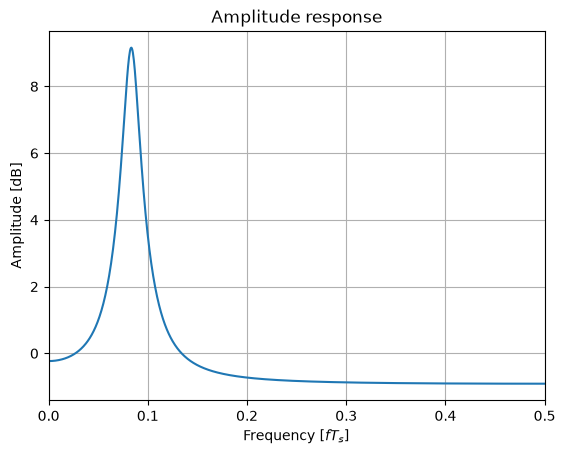

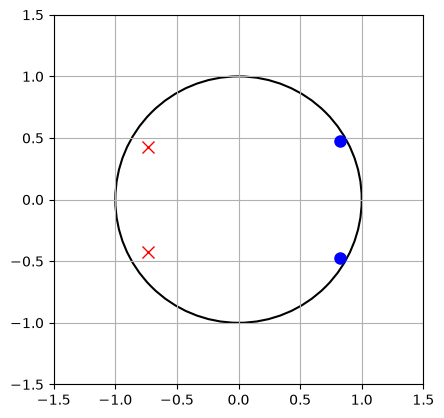

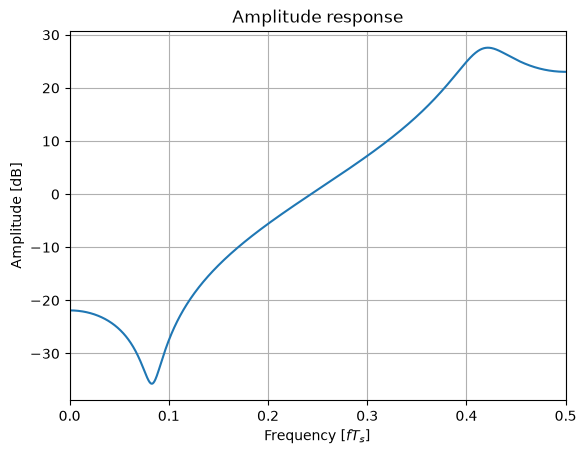

In [9]:
# Write your code here
# 1.
Bz = PolynomialMultiply((-1, 0.95*np.exp(np.pi/6*1j)),(-1, 0.95*np.exp(-np.pi/6*1j)))
Az = PolynomialMultiply((-1, 0.65*np.exp(np.pi/6*1j)),(-1, 0.65*np.exp(-np.pi/6*1j)))
plotFilter(Bz, Az)
# 2.
Bz = PolynomialMultiply((-1, 0.85*np.exp(np.pi/6*1j)),(-1, 0.85*np.exp(-np.pi/6*1j)))
Az = PolynomialMultiply((-1, 0.95*np.exp(np.pi/6*1j)),(-1, 0.95*np.exp(-np.pi/6*1j)))
plotFilter(Bz, Az)
# 3.
Bz = PolynomialMultiply((-1, 0.95*np.exp(np.pi/6*1j)),(-1, 0.95*np.exp(-np.pi/6*1j)))
Az = PolynomialMultiply((-1, 0.85*np.exp(5*np.pi/6*1j)),(-1, 0.85*np.exp(-5*np.pi/6*1j)))
plotFilter(Bz, Az)

<div class="alert alert-success">
1. The response attenuates at low frequencies and attenuates the most near f=Fs/12, due to the close zeros, and boosts higher frequencies due to the closer poles.
2. The response boosts frequencies near f=Fs/12, due to the close poles, and attenuates high frequencies due to the closer zeros.
3. The response is attenuated for low frequencies due to the zeros with positive real part (|alpha_z| < Pi/2), again with the most attenuation at f=Fs/12. Then the response rises, with a maximum at f=Fs*5*Pi/12, due to the pole there. For even higher frequencies it stays boosted because the poles are closer than the zeros.
</div>

## Design of an IIR *notch* filter

In this section, we shall design an IIR notch filter based on the **narrowband approximation**. A notch filter design problem is often formulated as: &ldquo;The goal of this filter is to completely suppress a particular (specified) frequency $F_c$ where $0<F_c<\fsamp/2$. While, as far as possible, the filter should leave all other frequencies untouched.&rdquo;

We need to translate these conditions into filter specifications before we can start with designing the filter. Thus, applying what we have learnt about filter design specifications we can come up with the following:

1. The normalised frequency $F_c\tsamp$ should be *completely* suppressed, where $F_c\tsamp$ is some value in the range $(0<F_c\tsamp<1/2)$
2. Let us define the (normalised) $3\unit{dB}$ bandwidth as $\text{BW}\,\tsamp$.
3. Filter should leave other frequencies untouched

<div class="alert alert-quiz">
    
Take the short quiz on IIR on Ufora
</div>

By answering the following questions, you will be led through the design of the filter.

<div class="alert alert-info">

**Theory questions**  
1. Engineering solutions should be efficient. Thus, in the absence of further information, we should aim for a design that is of *minimal complexity*. Keeping this in mind, what is the *minimum* order of the filter that could satisfy our constraints?
2. Where would you put the *poles* and *zeroes* of this filter? Remember what we have seen in the previous section and write the poles and zeros in polar coordinates can make your design easier.
3. Express the filter in its standard form of $H(z)$ based on your answer to the previous question. 
4. Which parameters are already fixed and which ones are free parameters? **hint:** There will be 2 free parameters.
5. Now: derive the form of $A(fT_s)$ for frequencies in the direct neighbourhood of $F_c$ in terms of the narrowband approximation. Assume, hereby, that $A(fT_s)$ at any frequency close to a pole or zero is mainly dominated by the effect of that pole or zero. Use this approximation to formulate a general expression for $A\big((F_c\pm\bw/2)T_s\big)$ in terms of the unknown filter parameters.


</div>

<div class="alert alert-success">

1. 2, because we need a complex pair of poles and zeros, so the order is 2

2. $\alpha _{z_2} = \alpha _{p_2} = - \alpha _{z_1} = - \alpha _{p_1}, r_{z_1} = r_{z_2} =~ 1, rp_1 = rp_2 =~ 1$ and $r_{p_{1,2}} < r_{z_{1,2}}$

3. $H(z)=b_0\frac{(z-z_0)\cdot(z-z_1)}{(z-p_0)\cdot(z-p_1)}$

4. $z_1 = z_0*$, $p_1 = p_0*$ because you want a real impulse response, $r_{z_{1,2}}=1$ because we want to completely filter out the notch frequency $F_C T_S$, assume the frequency $F_C$ is given, then the phases $\alpha _z$ and $\alpha _p$ are $2\pi \cdot F_C T_s$. The amplitude $r_p$ and $b_0$ are free parameters, $r_p$ being close to 1 and slightly less than $r_z$, and $b_0$ serving to filter out the DC and high amplitude gains.

5. in this region the transfer function can be approximated (assuming $p_1$ and $z_1$ can be ignored) with $A(fT_s)=b_0 \cdot |\frac{(z-z_0)}{(z-p_0)}|=b_0 \cdot |\frac{(e^{j*2\pi fT_s}-r_z e^{j*2\pi F_C T_s)}}{(e^{j*2\pi fT_s}-r_p e^{j*2\pi F_C T_s)}}|=b_0 \cdot |\frac{1-e^{j2\pi (F_C-f) T_s}}{1-r_p e^{j2\pi (F_C-f) T_s}}|$ 

$A((F_C +- \frac{BW}{2}) \cdot T_s)=b_0 |\frac{1-e^{j2\pi(F_C T_s-F_C T_s +- \frac{BW}{2} T_s}}{1-r_p e^{j2\pi(F_C T_s-F_C T_s +- \frac{BW}{2} T_s}}|=b_0 |\frac{1-e^{+-j2\pi \frac{BW}{2} T_s}}{1-r_p e^{+-j2\pi \frac{BW}{2} T_s}}|=b_0 \sqrt{\frac{(1-cos(+-2\pi\frac{BW}{2}T_s))^{2}+(sin(+-2\pi\frac{BW}{2}T_s))^{2}}{(1-r_p cos(+-2\pi\frac{BW}{2}T_s))^{2}+(r_p sin(+-2\pi\frac{BW}{2}T_s))^{2}}}=b_0 \sqrt{\frac{2-2cos(+-2\pi\frac{BW}{2}T_s)}{1-2r_p cos(+-2\pi\frac{BW}{2}T_s)+r_p^{2}}}$
</div>

Properly done, the above will lead you to a condition relating the amplitude response at the 3-dB frequencies with the unknown filter parameters. Now, proceed as follows:

1. Apply the conditions at a 3-dB frequency to express the position of the complex pole as a function of $b_0$. Solving this directly is hard. We shall therefore solve for the parameters in an *iterative* manner.
2. Start by *assuming* $b_0 = 1$,
3. Solve the expression for the 3-dB bandwidth (where $\fdsd[\cfqts]{A} = 1/\sqrt{2})$ to obtain the radius of the pole.
3. Insert this value for the complex pole in the true amplitude response and apply the condition of unit gain at $F=0$ or $F=F_s/2$ to find the value of the required filter gain ($b_0$). This will give you your first iterative update to $b_0$.
4. Apply this new value of $b_0$ in step 3 and find the new value of the complex pole (the radius).
5. Iterate steps 3-5 until the filter parameters do not change significantly over iterations. We term this state, where the iterative updates do not change the estimates any further, as convergence. The final values you obtain for the parameters define the filter.

<div class="alert alert-info">
    
Summarise this method into the form of a function `Bz, Az = NotchFilter(FcTs, BWTs)` that takes, as input, $F_cTs$, $\bw\,T_s$ and returns the filter coefficients in terms of the polynomials $\zds{B}$ and $\zds{A}$.
    
</div>

In [50]:
def NotchFilter(FcTs, BWTs, eps = 1E-15):
    cosphi = np.cos(2*np.pi*BWTs/2)
    expFcTs = np.exp(1j*2*np.pi*FcTs)
    expminFcTs = np.exp(-1j*2*np.pi*FcTs)
    b0, rp = 10, 10
    b0_n, rp_n = 1, 1
    
    while (abs(b0_n - b0) >= eps or abs(rp_n - rp) >= eps):
        b0, rp = b0_n, rp_n
        rp_n = cosphi - np.sqrt(cosphi**2-4*b0**2*cosphi+4*b0**2-1)
        b0_n = 1/np.abs((1-expFcTs)/(1-rp*expFcTs))
    
    return b0_n*GetComplexPairPoly((-1, 1*np.exp(1j*2*np.pi*FcTs))), GetComplexPairPoly((-1, rp_n*np.exp(1j*2*np.pi*FcTs)))

<div class="alert alert-info">
    
**Verification of filter design**  
Plot the amplitude response and pole-zero plot of this filter for:  
$F_c\tsamp = 1/6$ and $\bw\,\tsamp = \dfrac{1}{10\pi}$.  
Use these plots to verify that your design works well.
</div>

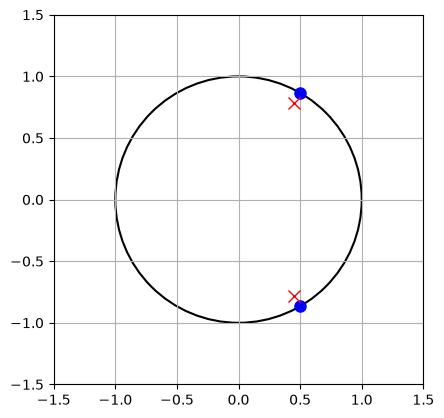

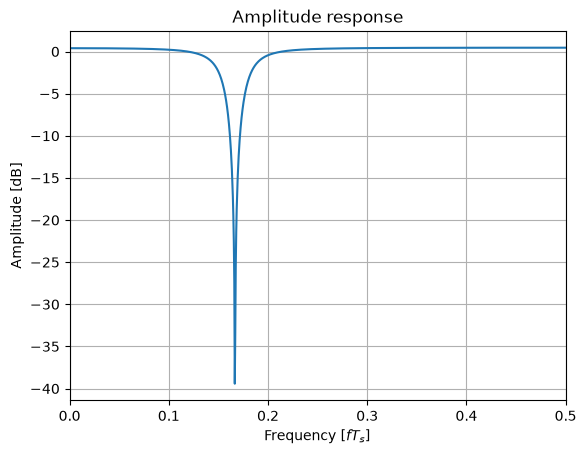

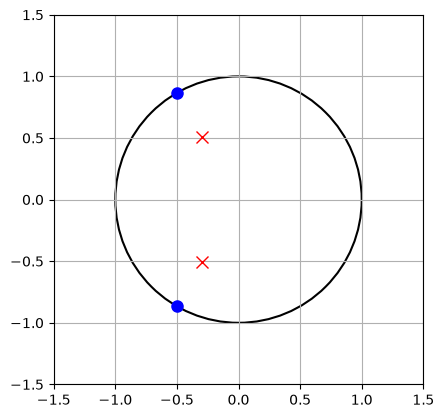

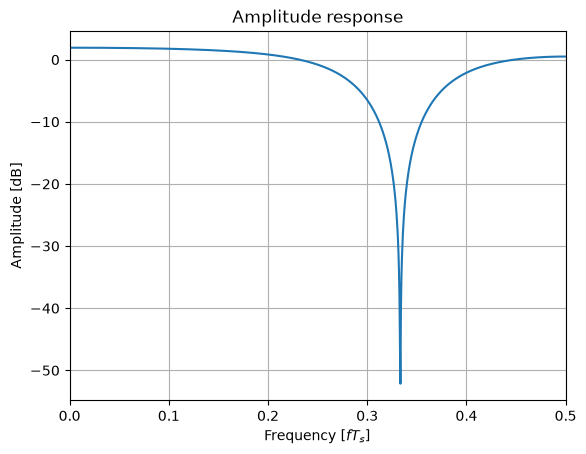

In [11]:
Bz, Az = NotchFilter(1/6, 1/(10*np.pi))

plotFilter(Bz, Az)

Bz, Az = NotchFilter(1/3, 5 * 1/(10*np.pi))

plotFilter(Bz, Az)

### Practical application of the notch filter

An audio sample corrupted by harmonic noise is given to you. Apply your brand-new notch filter to enhance this signal. First load and analyse the signal using the following steps:

<div class="alert alert-info">

1. Load the data first: `fs, x = wavf.read('noisy_hum.wav')`. `x` is the audio signal and `fs` is the sampling frequency of the signal.
2. Analyse the signal to see at what frequencies the interference lies. For this, compute the short term spectrogram of the signal with command `plotSpectrum(x, fs, n_window=2000, flim=(0,fs/2))`. The stft will be discussed later on in the course. For now it is sufficient to know that the stft plots the fourier spectrum of a small part of the signal and that this is repeated several times. In this manner, for each time instance (on the x-axis), the frequency components are plotted on the y-axis. The stft can display how the frequency content changes over time. **Hint:** To see at which frequencies the noise is located, you might want to zoom in on the lower frequencies by changing `flim`, or by interactive plot. Keep in mind that the figure should be zoomed into the appropriate region in the submission so that no manual adjustment is needed. 
    
</div>

In [12]:
## un-comment this cell if you need interactive mode
# %matplotlib notebook

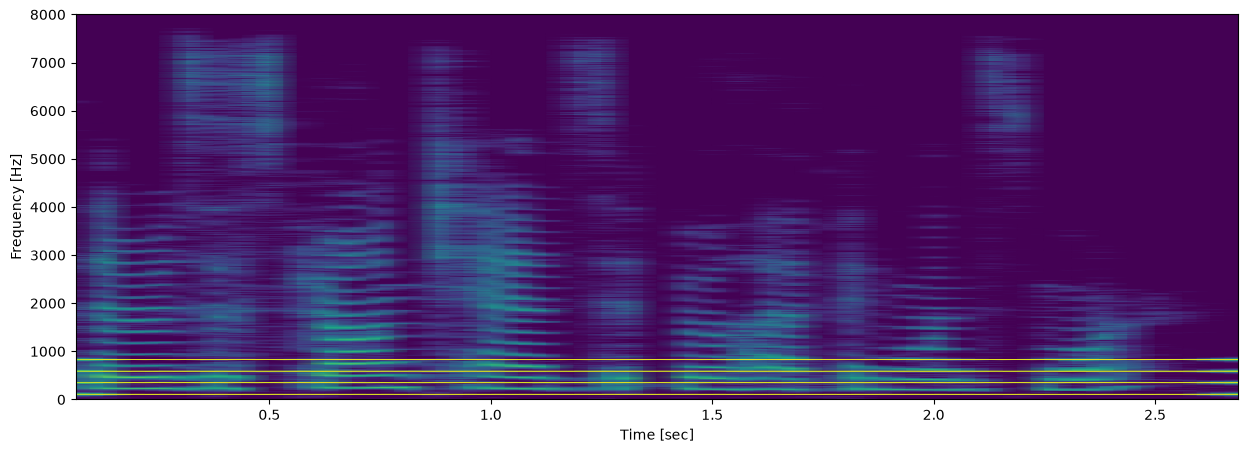

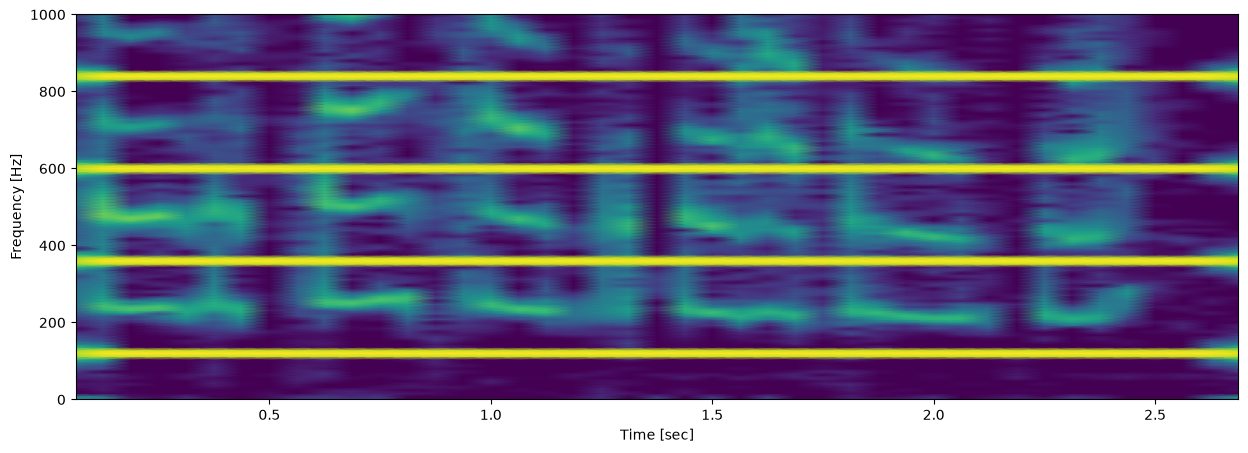

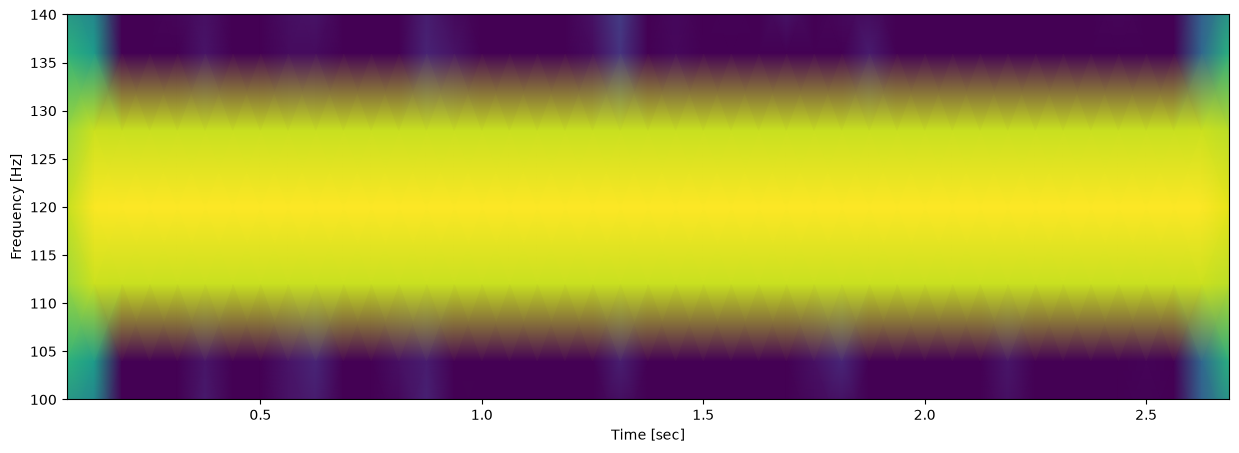

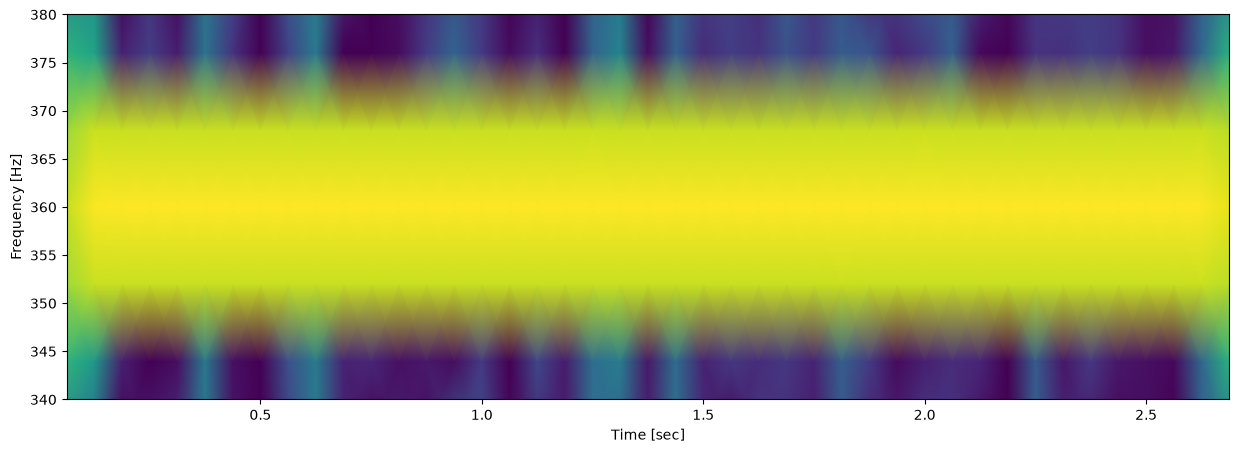

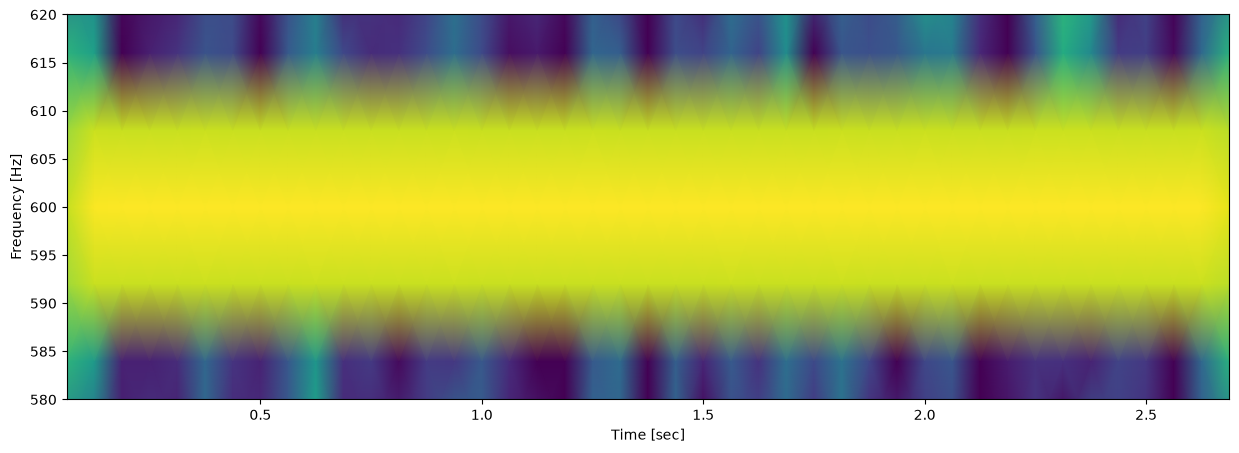

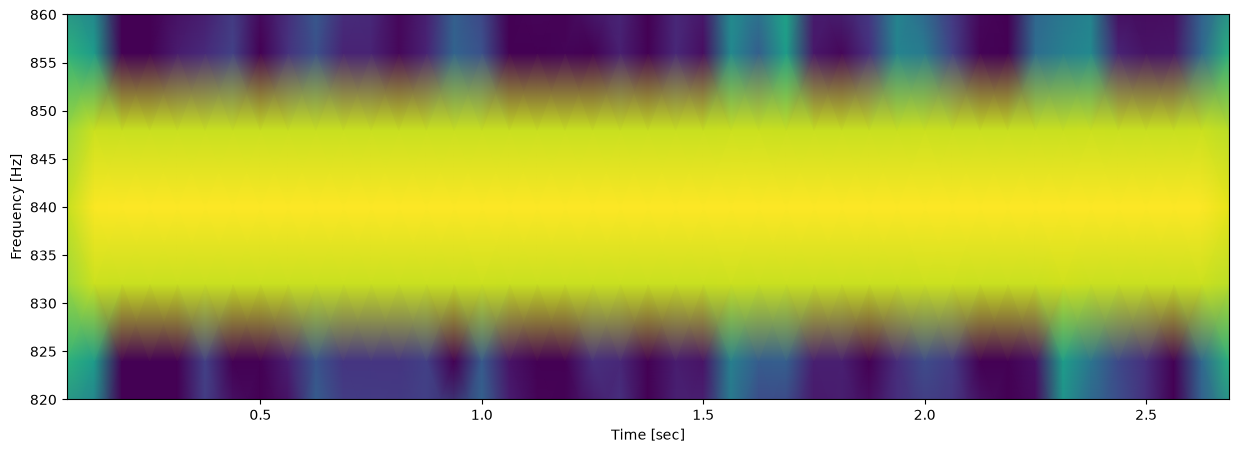

In [13]:
noisy_hum = 'assets/audio/noisy_hum.wav'
fs, x = wavf.read(noisy_hum)
x = x / 2**15
ipd.display(ipd.Audio(x, rate=fs))
#change 'flim' to zoom in at certain frequencies 
#or write your own funtion to see at what frequencies the interference is located
Sxx = plotSpectrum(x, fs, n_window=2000, flim=(0,fs/2))  
Sxx = plotSpectrum(x, fs, n_window=2000, flim=(0,1000))  
Sxx = plotSpectrum(x, fs, n_window=2000, flim=(100,140)) 
Sxx = plotSpectrum(x, fs, n_window=2000, flim=(340,380))
Sxx = plotSpectrum(x, fs, n_window=2000, flim=(580,620))
Sxx = plotSpectrum(x, fs, n_window=2000, flim=(820,860))   

<div class="alert alert-info">
    
You will see that there are multiple interfering frequencies. We will later design the notch filter(s) *individually* for the interfering frequencies. What will be the parameters that you will choose:
1. At what frequencies will you place the notch filters?
2. What BW will you choose? Justify your choice.
</div>

<div class="alert alert-success">

1. There are 4 visible lines (at 4 frequencies) in the spectrum plot above. We will place a notch filter with a frequency at the middle of each of these lines to filter out these noise frequencies.

2. We will choose the BW just large enough to filter out each noise band, but small enough so few other frequencies arre effected. 
</div>

<div class="alert alert-info">

Think: Would you apply the filters in cascade (series) or in parallel?

</div>

<div class="alert alert-success">
Series, if we would use parallel the noise frequencies would still pass in each one of the other filters.
</div>

<div class="alert alert-info">

Now form the combined filter and plot the pole-zero representation and its frequency response. State your observations. Are they in line with what you would expect?
</div>

In [14]:
# Code for your filter design
Ts = 1/fs
print(Ts)
Bz1, Az1 = NotchFilter(120*Ts, 30*Ts)
Bz2, Az2 = NotchFilter(360*Ts, 30*Ts)
Bz3, Az3 = NotchFilter(600*Ts, 30*Ts)
Bz4, Az4 = NotchFilter(840*Ts, 30*Ts)

Bz = np.real(PolynomialMultiply(PolynomialMultiply(PolynomialMultiply(Bz1, Bz2), Bz3), Bz4))
Az = np.real(PolynomialMultiply(PolynomialMultiply(PolynomialMultiply(Az1, Az2), Az3), Az4))

6.25e-05


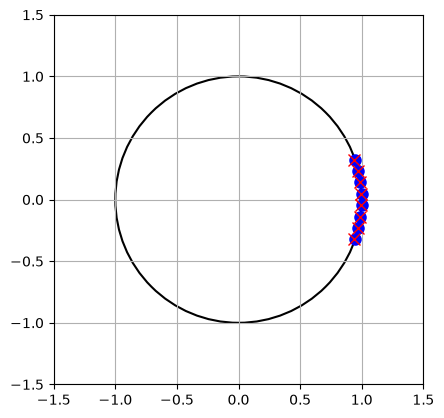

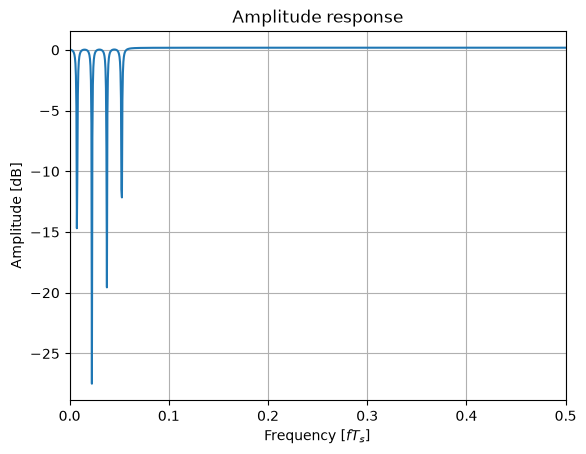

In [15]:
# Code for the plots
plotFilter(Bz, Az)

<div class="alert alert-success">
Yes, the difference in how deep the peeks go is due to inaccuracies in the plot.
</div>

<div class="alert alert-info">

Apply the combined filter to the noisy signal $\matcmd[]{x}$. Have a look at the [`lfilter`][lfilter] from ´scipy.signal` on how to implement this.

Now use the `plotSpectrum()` function to compare the original and the processed signal and demonstrate, hereby, the effect of the notch filter.

Don't forget to listen to the processed signal... and feel proud!
</div>

[lfilter]: https://docs.scipy.org/doc/scipy/reference/generated/scipy.signal.lfilter.html

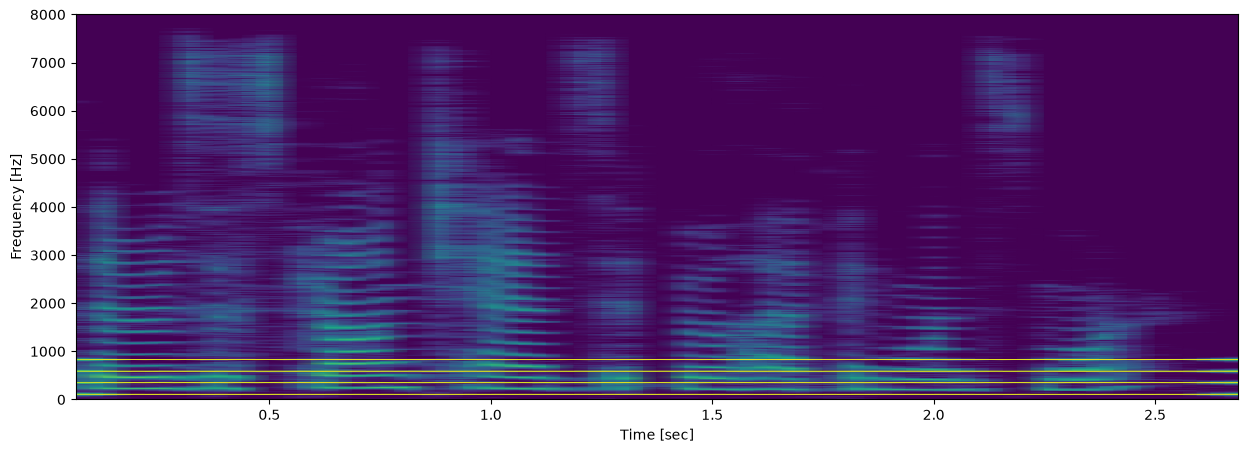

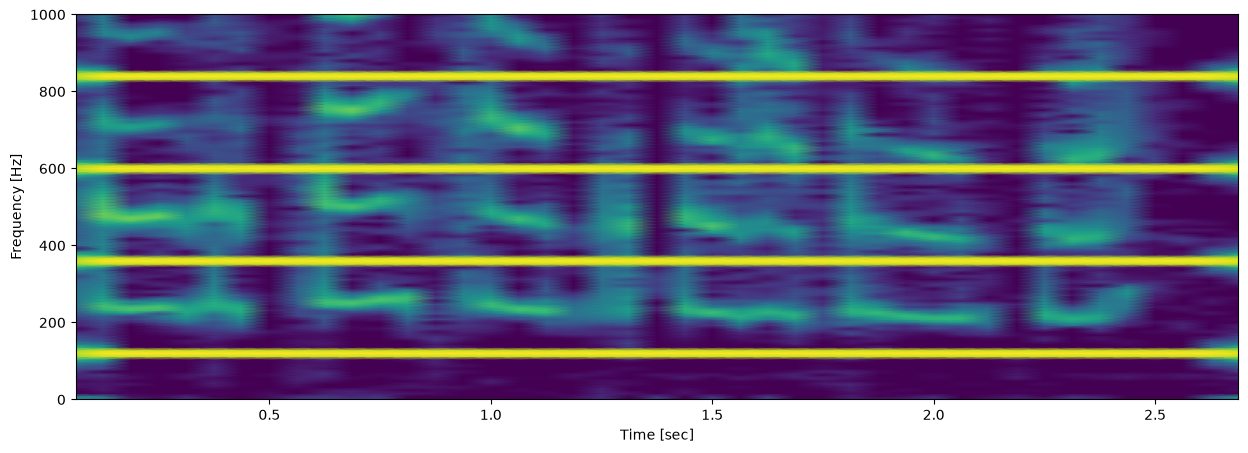

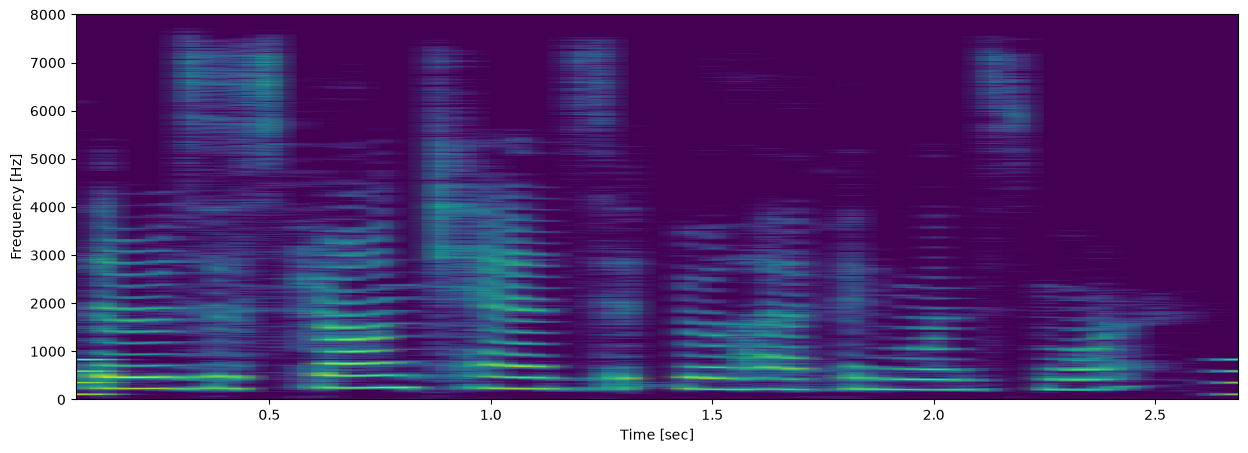

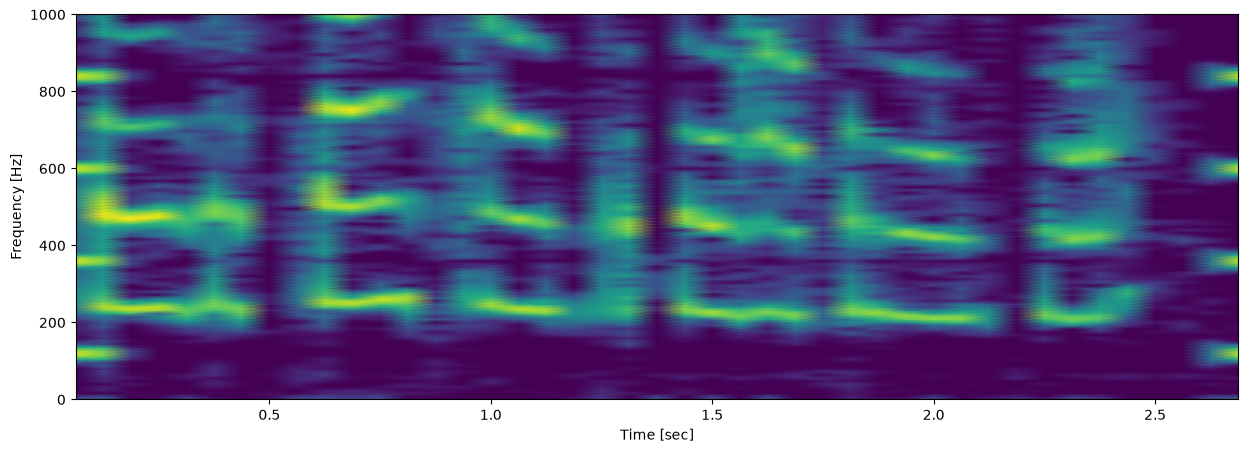

In [16]:
# Filter the noise signal x and plot the new spectogram 
from scipy.signal import lfilter

x_filtered = lfilter(Bz, Az, x)
ipd.display(ipd.Audio(x_filtered, rate=fs))

# Compare original and filtered frequency spectra
Sxx_original = plotSpectrum(x, fs, n_window=2000, flim=(0, fs/2))
Sxx_original = plotSpectrum(x, fs, n_window=2000, flim=(0, 1000))
Sxx_filtered = plotSpectrum(x_filtered, fs, n_window=2000, flim=(0, fs/2))
Sxx_filtered = plotSpectrum(x_filtered, fs, n_window=2000, flim=(0, 1000))

<div class="alert alert-success">
The filter does not seem to work immediately, but after about 0.15s the noise gets filtered out very well.
</div>

<div class="alert alert-info">
    
Include your processed signal in the deliverable. Name this file `group_xx_notch_output.wav`, where `xx` is your group number. place it in the `./data/results` folder.
</div>

In [17]:
#save the reslting
x_filtered = x_filtered * 2**15
x_filtered = np.real(x_filtered.astype(np.int16))
wavf.write('./assets/audio/results/group_xx_notch_output.wav',fs,x_filtered)

## ... and some practical pitfalls to be aware of (and avoid!)

In this part we will complement our journey in filter design by investigating certain practical aspects. You will learn how numerical errors in representing filter coefficients can have unexpected consequences. You will also learn how to avoid such issues. We have seen this _theoretically_ and now we shall put this theory into practice.

<div class="alert alert-info">

**Task**
    
In the lecture we have seen that numerical inaccuracies in representing the polynomial coefficients can lead to the roots of the polynomial falling on or outside the unit circle.
    
* How does this affect the stability of an IIR filter?
* How does this affect the stability of an FIR filter?
    
Justify your answers in both cases.
    


<div class="alert alert-success">

IIR filters:

For IIR filters, all the poles must lie strictly inside the unit circle. If not, the filter is no longer BIBO stable. If all poles are strictly inside the unit circle however, the filter will be BIBO stable and $\sum_n |h[n]| < \infty$. If there are no poles outside the unit circle, but there is at least 1 pole on the unit circle, so $|p_k|=1$, then the filter will only be marginally stable, and $h[n]$ will contain a term like $\cos(2\pi F_p T_s n)$, which never decays and $h[n]$ is not absolutely summable. If a pole outside the unit circle is present, $h[n]$ will contain a term like $r^n$ with $r>1$, which grows exponentially with n, meaning the filter will be unstable.


FIR filters:

For FIR filters, $H(z)=B(z)$, which means these filters can only ever contain poles at z=0, and thus no poles can exist on or outside the unit circle. The impulse response has a finite length, so therefore $\sum_n |h[n]| = \sum_{n=0}^{N-1} |b_n| < \infty$. An FIR filter is therefore always BIBO stable.
</div>

We shall take a hands-on look at this effect for IIR filters. Specifically, we shall continue using the notch filter we designed previously, which was realised as a 2nd order IIR filter, and denote the notch-filter that notches (normalised) frequency $F_i\tsamp$ in the standard form as: $\fds{H_i} = \dfrac{\fds{B_i}}{\fds{A_i}}$. 

Assuming we have several frequencies ($F_1, F_2,\ldots, F_I$) that we wish to notch _simultaneously_ then we can generate 2nd order notch filters $\fds{H_i}$ for _each_ frequency $F_i$ and apply these filters to the signal. 

The _application_ of the filters can be done in two ways, which we shall call the _combined_ and the _cascaded_ manner.

* **combined** application: here we _explicitly_ multiply the different transfer functions $\fds{H_i}$ to generate a _single_ combined transfer function $\fds{H}$. Thus, for the set of notch frequencies $F_i \in \{F_1, F_2,\ldots\,,F_I \}$, the IIR filter corresponding to the combined transfer function can be represented as:
$$\fds{H} = \dfrac{\prod_{i=1}^{I} \fds{B_i}}{\prod_{i=1}^{I} \fds{A_i}}  = \dfrac{\fds{B}}{\fds{A}}$$
The output of this filter is then obtained by $\fds{Y} = \fds{H}\fds{X}$. Think of this as designing a _single_ long filter that notches all frequencies in the given set.

* **cascade** application: here, we process the input in a _sequential_ manner, through the set of _individual_ notch filters. With the output of a previous stage being the input to the next stage, mathematically, we have:
$$\fds{Y_{i}} = \fds{H_{i}}\fds{Y_{i-1}}$$ and $\fds{Y_0} = \fds{X}$. Think of this as _several_ 2nd order notch filters joined in series, where each notch filter is responsible for notching only a single frequency.

From the above explanation, it should be evident that whereas in the case of the cascade application, the poles and zeros of the system correspond to the poles and zeros of the individual notch filters $\fds{H_i}$, for the case of the combined system, the true poles and zeros are obtained by calculating the roots of the respective polynomials $\fds{A}$ and $\fds{B}$. Similarly, the total amplitude response in the cascaded application is the _product_ of the individual amplitude responses whereas, in the _combined_ application, this must be computed as the amplitude response of the resulting filter $\fds{H}$.

In theory, _both_ applications are identical and should yield the same result. But what do we see in practice? We shall see this by comparing the behaviour of the _combined_ notch filter that filters several different frequencies against the _cascaded_ version.

Consider $\fsamp = 16\unit{kHz}$. We consider that we have a desired signal corrupted by narrowband noise consisting of the power-supply hum $F_0=50\unit{Hz}$ and a *variable* number of *even* harmonics $QF_0$ where $Q = 2,4,\ldots,$. To clarify: if $Q=2$, it implies that the input signal is assumed to contain interfering signals at $F_0$ and $2F_0$, both of which frequencies must then be notched. If $Q=4$, the set of frequencies to notch becomes $\cbr{F_0, 2F_0, 4F_0}$, and so on...:
<div class="alert alert-info">

1. Create the appropriate set of notch filters $\fdvar[q]{H}(z)$ for a 3-dB bandwidth of $\bw = 5\unit{Hz}$ to notch the harmonics present in that situation.
2. Start with $Q=6$, compute the combined filter $\zds{H}$ and make the pole-zero plot. Also plot the amplitude response of this combined filter. 
3. Do the same with the cascade filter $\zds{H^{\prime}}$. **Note:** you will have to make your own plot funtions for the series implementation.

</div>

In [18]:
# Code for the filters
from scipy.signal import lfilter
def NotchFilterHarmonicsCombined(Q = 6, F0 = 50, BW = 5, Ts = 6.25E-5):
    B, A = (1), (1)
    for i in [1] + list(range(2, Q+1, 2)):
        Bi, Ai = NotchFilter(i*F0*Ts, BW*Ts)
        B = PolynomialMultiply(B, Bi)
        A = PolynomialMultiply(A, Ai)
    return B, A

def NotchFilterHarmonicsCascade(Q = 6, F0 = 50, BW = 5, Ts = 6.25E-5):
    samplescount = 2048
    Htot = np.ones(samplescount)
    zeros, poles = np.zeros((Q//2+1)*2, dtype=complex), np.zeros((Q//2+1)*2, dtype=complex)
    
    for i in [0.5] + list(range(1, Q//2+1)):
        Bi, Ai = np.real(NotchFilter(2*i*F0*Ts, BW*Ts)) # Calculation errors that lead to small imaginairy coefficients are being removed
        zeros[int(i)*2: int(i)*2+2] = np.roots(Bi)
        poles[int(i)*2: int(i)*2+2] = np.roots(Ai)

        _, H = freqz(Bi, Ai, worN=samplescount)
        Htot *= np.real(H)

    return Htot, zeros, poles


In [19]:
def zPlane2(zeros, poles, xlim=(-1.5,1.5), ylim=(-1.5,1.5)):
    
    fig, ax = plt.subplots()
    ax.plot(np.real(zeros), np.imag(zeros), 'o',color='b', markersize=8)
    ax.plot(np.real(poles) , np.imag(poles) , 'x', color='r', markersize=8)
    ax.set_xlim(np.array(xlim))
    ax.set_ylim(np.array(ylim))

    ax.add_artist(plt.Circle((0, 0), 1, fill=False, color='black', linewidth= 1.5))
    ax.set_aspect('equal')
    ax.grid(True)

def plotAmplitude2(H, flim=(0, 0.5), fs=1):

    W = np.linspace(0, 0.5, len(H))
    fig = plt.figure()
    ax = fig.add_subplot()
    ax.plot(W,20*np.log10(np.minimum(1e4,np.maximum(1e-5,np.abs(H)))))
    
    ax.grid(True)
    ax.set_xlim(flim)
    ax.set_ylabel('Amplitude [dB]')
    if fs == 1: #normelised frequency
        ax.set_xlabel('Frequency [$fT_s$]')
    else:
        ax.set_xlabel('Frequency [$Hz$]')
    ax.set_title('Amplitude response for Cascade')


def plotFilter2(H, zeros, poles, flim=(0, 0.5), xlim=(-1.5,1.5), ylim=(-1.5,1.5), fs=1):
    
    ## plot z-plane
    zPlane2(zeros, poles, xlim, ylim)
    
    ## plot amplitude
    plotAmplitude2(H, flim=flim, fs=fs)

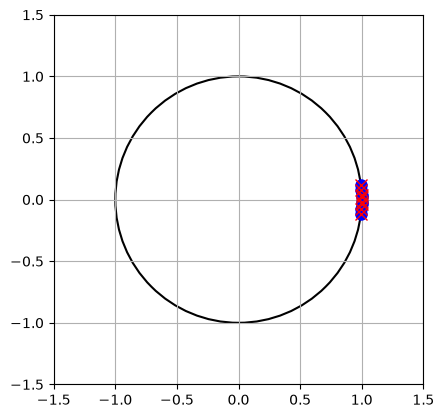

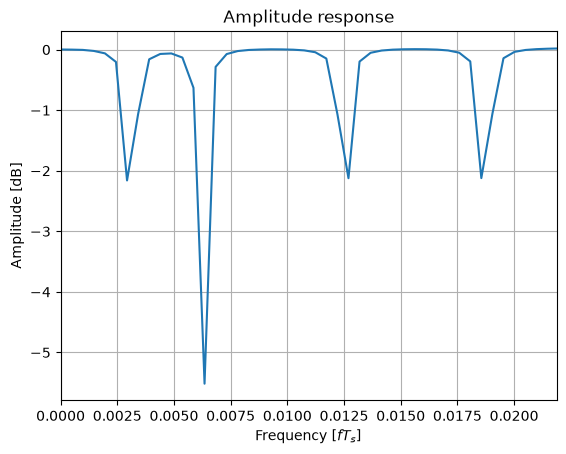

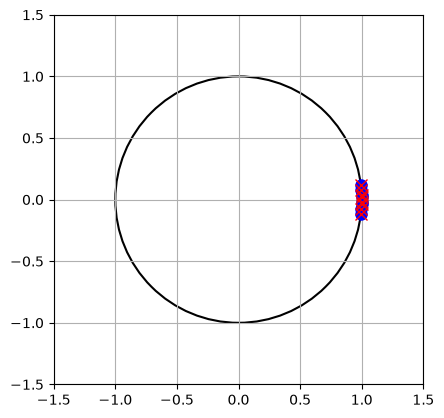

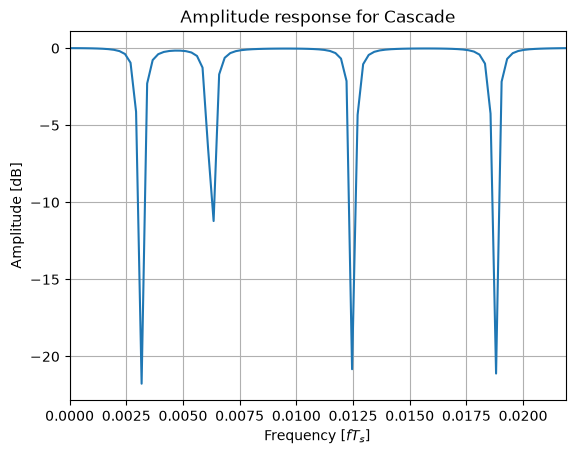

In [20]:
Q = 6
F0 = 50
BW = 5

# Code for the plots of the filters. Only keep the interesting figures that you discuss in your awnsers below!
B, A = NotchFilterHarmonicsCombined(Q = Q, F0 = F0, BW = BW)
plotFilter(B, A, flim=(0, (Q+1)*F0*Ts))

H, zeros, poles = NotchFilterHarmonicsCascade(Q = Q, F0 = F0, BW = BW)
plotFilter2(H, zeros, poles, flim=(0, (Q+1)*F0*Ts))

<div class="alert alert-info">

    
Answer the following questions:

1. Essentially, $\zds{H}$ and $\zds{H^{\prime}}$ should yield the same filter. What can you say about the poles of $\zds{H}$ as $Q$ increases? What happens e.g., for $Q = 12$ and $Q = 14$?
2. Based on your observations, explain (briefly) how you would implement a long IIR filter $\fds{H} = \dfrac{\fds{B}}{\fds{A}}$ in practice to avoid unexpected results.
    
</div>

In [21]:
# Code for the filters
# see above, the code for the filters remains unchanged

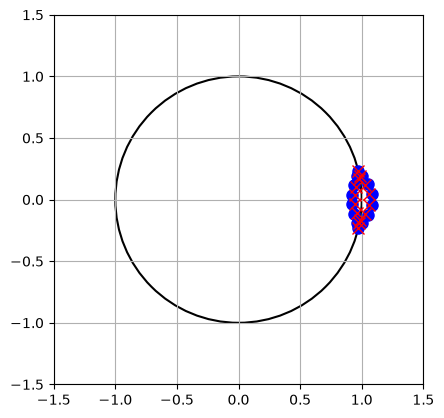

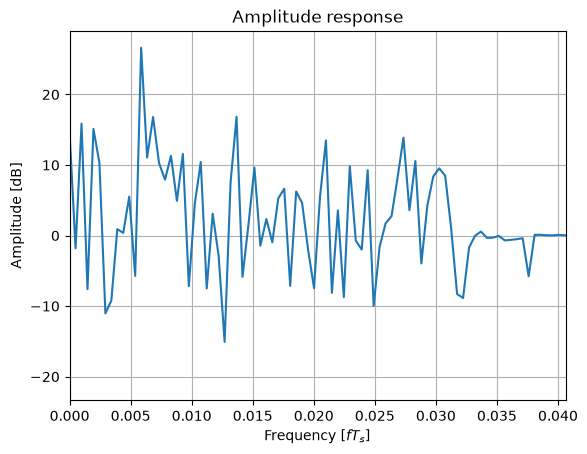

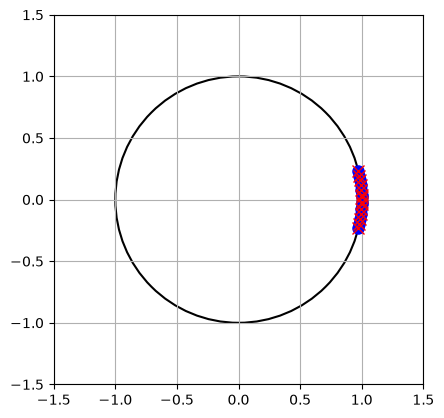

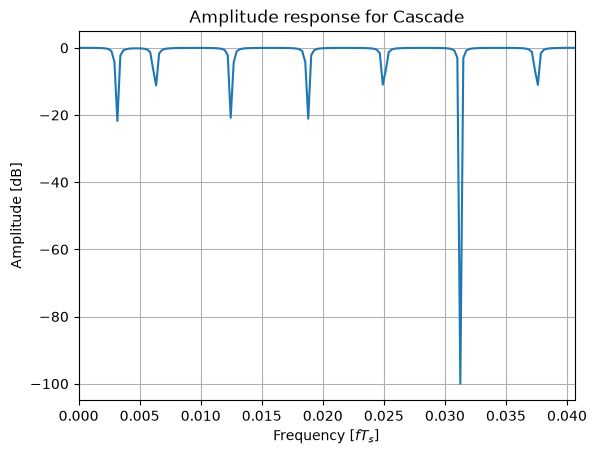

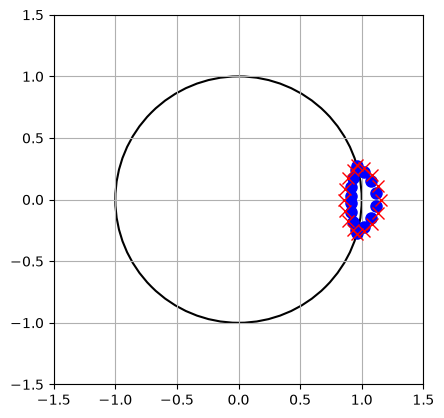

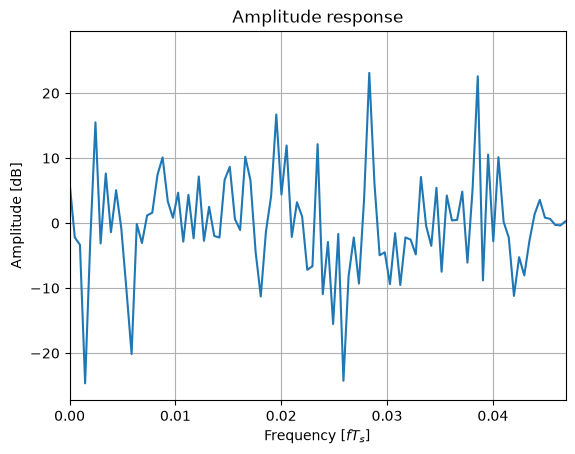

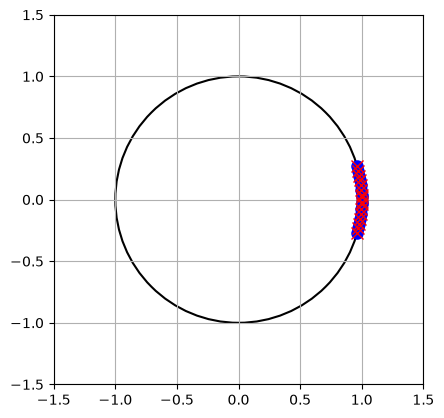

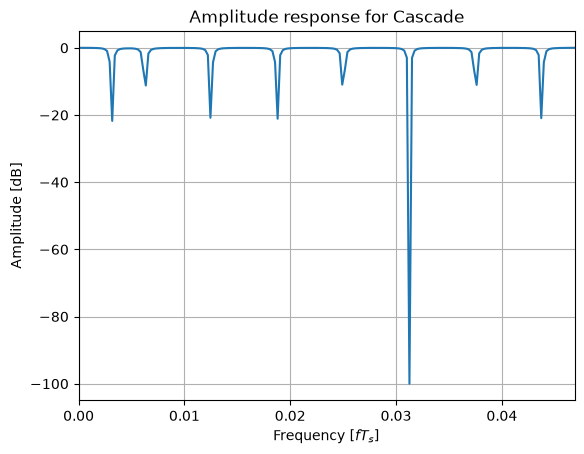

In [22]:
# Code for the plots of the filters. Only keep the interesting figures that you discuss in your awnsers below!
Q = 12
B, A = NotchFilterHarmonicsCombined(Q = Q, F0 = F0, BW = BW)
plotFilter(B, A, flim=(0, (Q+1)*F0*Ts))

H, zeros, poles = NotchFilterHarmonicsCascade(Q = Q, F0 = F0, BW = BW)
plotFilter2(H, zeros, poles, flim=(0, (Q+1)*F0*Ts))

Q = 14
B, A = NotchFilterHarmonicsCombined(Q = Q, F0 = F0, BW = BW)
plotFilter(B, A, flim=(0, (Q+1)*F0*Ts))

H, zeros, poles = NotchFilterHarmonicsCascade(Q = Q, F0 = F0, BW = BW)
plotFilter2(H, zeros, poles, flim=(0, (Q+1)*F0*Ts))

<div class="alert alert-success">

1. For Q = 6, both filters work fine. For Q = 12 or Q = 14 however, the combined filter introduces poles with amplitudes greater than 1, making the filter act weirdly around the frequencies it is supposed to filter out. The cascade filter works as intended for these frequencies.

2. I would choose the cascade filter to make sure the filter works as intended.

</div>

## Adaptive filtering for echo cancellation

In communications scenarios, especially in hands-free telephony, we are often confronted by the problem of *echo*. Assume you are in a telephone conversation with your friend. Your friend's speech signal (called the far-end speaker in the literature) is played back by the loudspeaker of your device. This loudspeaker signal, modified by the room acoustics, is picked up by the microphone, along with your speech (which is usually termed the near-end or desired signal). This pick-up of the loudspeaker signal is termed the *echo*. If no signal processing is done, this combination of your friend's speech and your speech is transmitted back and your friend has the annoying experience of having his/her words thrown back at him, quite literally. Especially in hands-free communications, the loudspeaker is much closer to the microphone and, therefore, the echo component can drown out the desired signal. In the interests of sanity and preserving the friendship, something must be done!

### Enter the echo canceller

Mathematically, we can model this problem as follows. Assume we have signal $\tds[n]{x}$ (the microphone signal) which consists of a desired signal component $\tds[n]{s}$ (your speech) and an interfering signal component (the echo) $\tds[n]{v}$. The model is: $\tds[n]{x} = \tds[n]{s} + \tds[n]{v}$.

Assume, further, that the interfering signal $\tds[n]{v}$ is generated by an *unknown* system $h^{\prime}(n)$ (the room acoustics), acting on the *known* signal $v^{\prime}(n)$ (the signal that is received and played back by the loudspeaker) i.e., $\tds[n]{v} = h^{\prime}(n)\ast v^{\prime}(n)$. We have the signal $v^{\prime}(n)$ and we wish to use this knowledge to design an adaptive filter to *cancel* $\tds[n]{v}$ in $\tds[n]{x}$, leaving only the desired signal component $\tds{s}$.

Think! Do you notice the similarity between this problem and the problem of unknown system identification we have seen in the lecture?

Let us try to implement the echo cancelling filter step-by-step using the NLMS algorithm. The general sequence of programming the filter is as follows:

1. We define an $M-$tap adaptive filter $\mathbf{h} = [h_0,h_1,\ldots,h_{M-1}]$. This is the FIR adaptive filter, which we shall use to estimate the unknown system $h^{\prime}(n)$
2. Start with some initial estimate of $\mat{h}$. E.g., all zeros or all ones or random values. It does not matter.
3. Now, iterate through the samples $\tmidx$ of the signal to adapt the filter. This is done as follows. For *each* sample $\tmidx$:
  1. let $\tds{\mat{h}}$ be the *estimate* of the adaptive filter at that time instant.
  2. compute the estimate $\widehat{v}(n)$ of $\tds[n]{v}$, i.e, $\widehat{v}(n) = h(n)\ast v^{\prime}(n) =\sum_{\idxa}h_{\idxa}(n) \tds[\tmidx-\idxa]{v^{\prime}}$
  3. compute the error signal $\tds{r} = \tds[n]{x}-\widehat{v}(n)$. Note that this error is *biased* by the desired signal component $\tds[n]{s}$. However, since $\tds[n]{s}$ and $\tds[n]{v}$ are usually uncorrelated with each other, this bias usually does not affect the estimate of $h^{\prime}(n)$ much if a small step-size is chosen in the update rule.
  4. by the method of stochastic gradient (specifically, NMLS), use this error signal to compute the updated filter $\tds[\tmidx+1]{{\mat{h}}}$, to be used for the next sample. **Tip:** Take proper precautions to prevent divide-by-zero errors! **Note:** The notations (signal names) might differ from your course notes. First identify which signals correspond with each other!
  4. The quality of the estimate $\widehat{\mat{h}}$ and the resulting output signal $\tds{\widehat{s}} = \tds{r}$ depends, quite strongly, on the parameters chosen for the NLMS. These parameters are: the stepsize $\alpha$ and the filter length $M$. You might need to play with these to get the best results.

<div class="alert alert-quiz">
    
Take the short quiz on adaptive filters on Ufora
</div>


<div class="alert alert-info">
    
First give the NLMS update formula in terms of h, $v^{\prime}$, r and $\alpha$, 
    
</div>

<div class="alert alert-success">
    
$h_m(n+1) = h_m(n) + 2 \alpha r(n) \cdot \frac{x(n-m)}{\sum_{k=0}^{N-1}{x^2(n-m)}}$
</div>

<div class="alert alert-info">

Implement the code for such a filter. The filter should receive as input the entire signal $\tds{x}$, $\tds{v^{\prime}}$, $\alpha$ and $M$. It should output the estimate of the unknown system $\mat{h}$ and the enhanced signal $\tds{\widehat{s}} = \tds{r}$.  
    
Use the following template:
    
</div>

In [23]:
def NLMSCanceller(x, vprime, alpha = 0.5, M = 10, eps=1E-12):
    N = max(len(x), len(vprime))
    x = np.pad(x, (0, N - len(x)))
    vprime = np.pad(vprime, (0, N - len(vprime)))
    #print(x, vprime)

    hEst = np.ones(M)
    sEst = np.zeros(N)

    # vpad = [0, 0, ..., 0, v'[0], v'[1], ..., v'[N]] = M-1 zeros, vprime
    vpad = np.concatenate((np.zeros(M - 1), vprime))
    #print(vpad)

    for n in range(N): 
        # vvec = [v'[n], v'[n-1], ..., v'[0], 0, 0, ..., 0] (len M)
        # vvec = [v'[n], v'[n-1], ..., v'[n-M]] (len M)
        vvec = vpad[n:n + M][::-1]
        
        #print(vvec)

        # Echo estimate = vhat(n) = sum(h_k(n) * v'[n-k])
        vhat = hEst @ vvec

        # Error signal r = x[n] - vhat(n)
        r = x[n] - vhat
        sEst[n] = r
        #print("n = ", n, "\nr = ", r, "\nsEst = ", sEst)

        hEst = hEst + 2 * alpha * r * vvec / (vvec @ vvec + eps)

    return hEst, sEst

#### Sanity check on the filter

<div class="alert alert-info">
    
1. Generate a signal `vprime = np.random.randn(10000)`
2. Generate the signal $\matcmd[]{x}$ as: `x = np.append(np.zeros(3), vprime[:-3])`
    
</div>

Where $\tds{x}$ is a filtered version of $\tds{v^{\prime}}$. There is no $\tds[n]{s}$ as of yet.

In [24]:
vprime = np.random.randn(10000)
x = np.append(np.zeros(3), vprime[:-3])

<div class="alert alert-info">

1. What unknown filter $\tds{h^{\prime}}$ does this correspond to?
2. What should you obtain as $\matcmd[]{hEst}$?
3. What should $\matcmd[]{sEst}$ be, if the filter correctly estimated?
</div>

<div class="alert alert-success">

1. The room acoustics only delay (3) the input signal, so h' = [0, 0, 0, 1, 0, 0, ..., 0]

2. hEst should be as close as possible to h', so also hEst = [0, 0, 0, 1, 0, 0, ..., 0]

3. sEst should be all zeros, as no speech is added to the signal, only a delay.

</div>

<div class="alert alert-info">

4. Apply your `NLMSEchoCanceller()` function to this data. Plot your results ($\matcmd[]{hEst}$ and $\matcmd[]{sEst}$) for $\alpha=\cbr{0.1,0.25,0.5}$. Comment on the results.
</div>

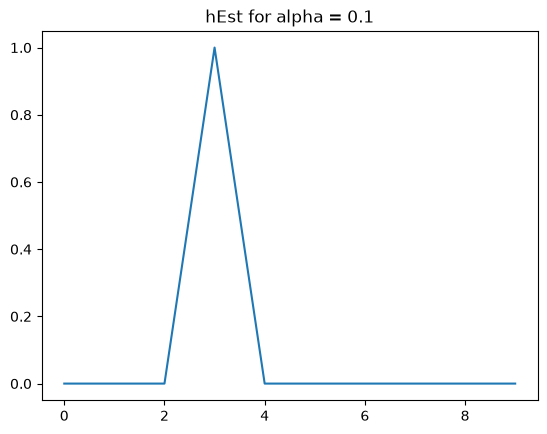

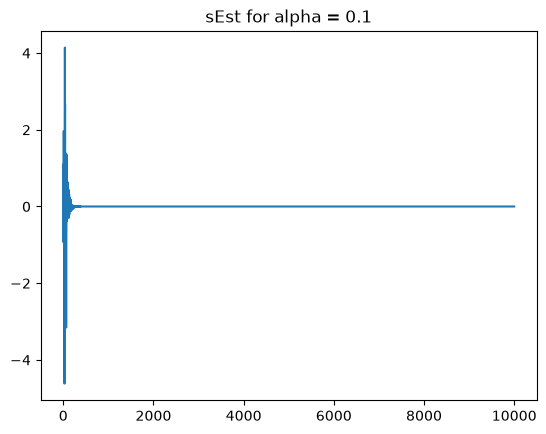

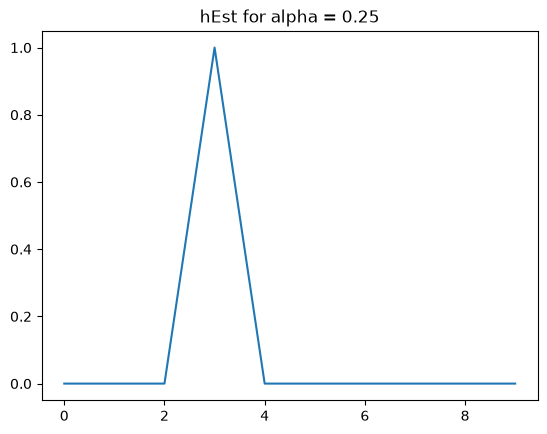

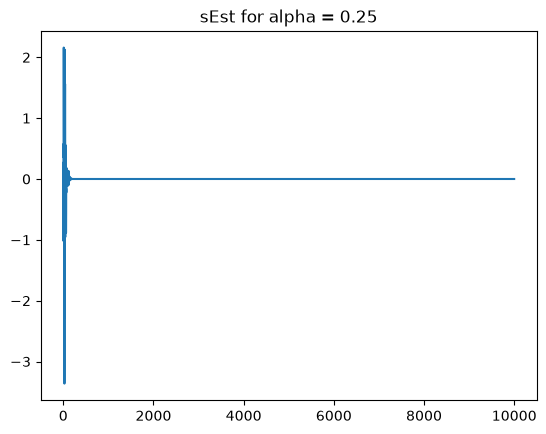

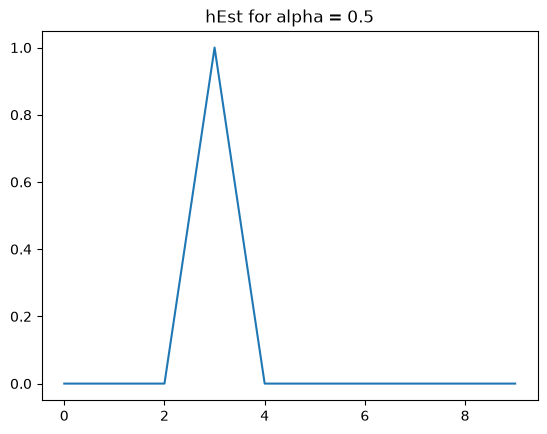

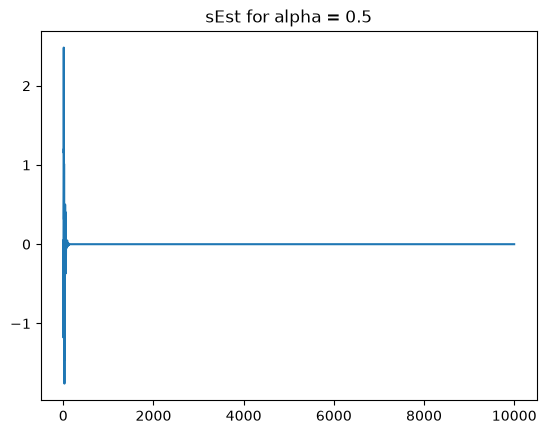

In [25]:
# Sanity check code here
alpha_list = [0.1, 0.25, 0.5]
for alpha in alpha_list:
    hEst, sEst = NLMSCanceller(x, vprime, alpha)
    plt.figure()
    plt.plot(hEst)
    plt.title("hEst for alpha = " + str(alpha))
    plt.show()
    
    plt.figure()
    plt.plot(sEst)
    plt.title("sEst for alpha = " + str(alpha))
    plt.show()

<div class="alert alert-success">

We can clearly see that hEst is a delta function $\delta (3)$, meaning it is 0 for all values except 3, for which it jumps to 1. This lines up with our expectations.

We also see that sEst converges to for each case of $\alpha$, however, for higher values of $\alpha$, sEst converges faster than for lower values. This all lines up with expectations
</div>

#### Sanity check of your understanding

<div class="alert alert-info">
    
Now another situation:
1. Generate a signal `vprime = rng.random(10000)`
2. Generate the signal $\matcmd[]{x}$ as: `x = np.append(vprime[3:], np.zeros(3))`
    
</div>

In [26]:
# Doesnt make any sence, the microphone is picking up the signal before the speakers ever play it.
vprime = rng.random(10000)
x = np.append(vprime[3:], np.zeros(3))
print(vprime)
print(x)
print(vprime[3:]-x[:-3])

[0.29800563 0.75694884 0.49714078 ... 0.06668501 0.8769057  0.0216577 ]
[0.9538136  0.21976876 0.11893121 ... 0.         0.         0.        ]
[0. 0. 0. ... 0. 0. 0.]


<div class="alert alert-info">

1. What unknown filter $\tds{h^{\prime}}$ does this correspond to?
</div>

<div class="alert alert-success">

The ideal impulse response should be $\delta(-3)$, which is a non-causal filter and thus our current code does not support this.
</div>

<div class="alert alert-info">

2. Apply your NLMS filter estimation to this data. Comment on the results.
</div>

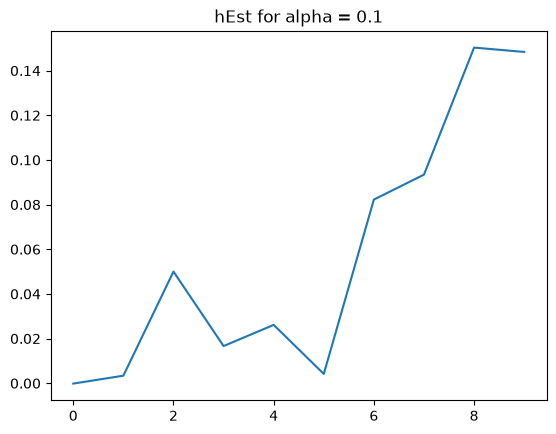

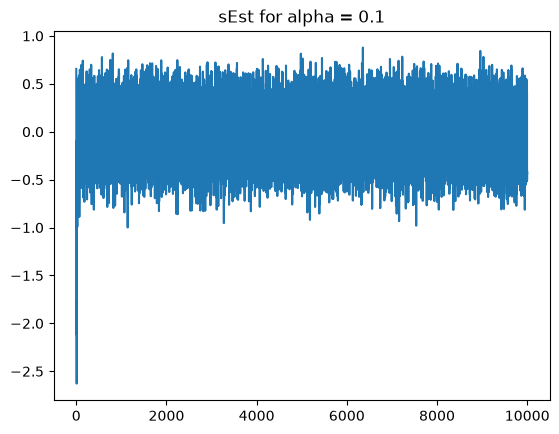

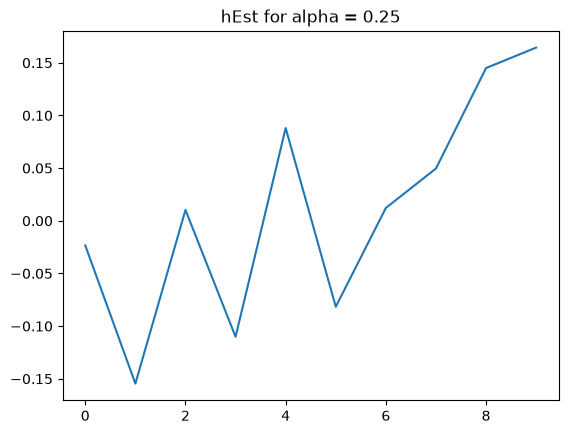

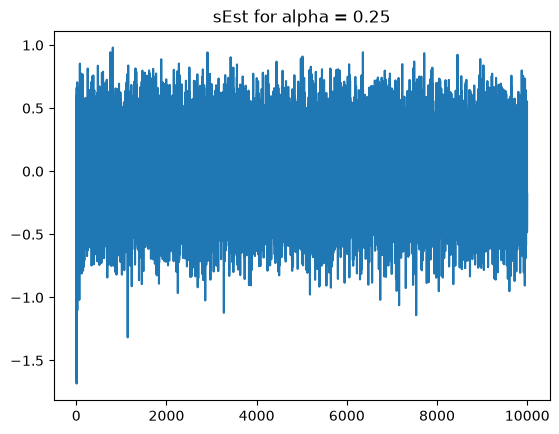

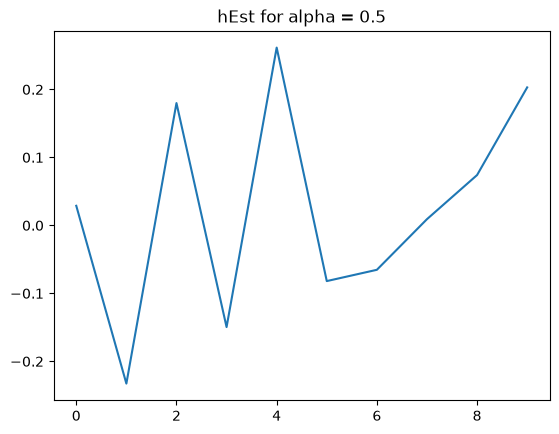

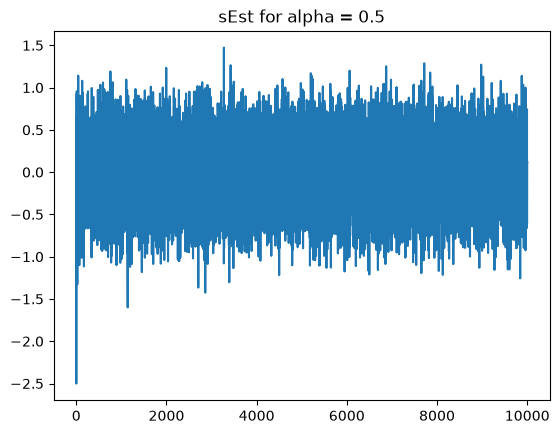

In [27]:
# Sanity check code here
# Sanity check code here
alpha_list = [0.1, 0.25, 0.5]
for alpha in alpha_list:
    hEst, sEst = NLMSCanceller(x, vprime, alpha)
    plt.figure()
    plt.plot(hEst)
    plt.title("hEst for alpha = " + str(alpha))
    plt.show()
    
    plt.figure()
    plt.plot(sEst)
    plt.title("sEst for alpha = " + str(alpha))
    plt.show()

<div class="alert alert-success">

As expected, we see that our impulse response hEst and speech signal sEst are not very useful, as our impulse response does not support negative indices for a non-causal case. Neither would it need to support this for any real scenario. Only in this artificial case, our microphone is picking up the noise signal before our speakers ever play this noise, the room acoustics therefore has a non-causal impulse response, and so hEst should be non-causal as well.

Basically, our filter does not know how to handle this artificial case, because the room acoustics work non-causally in this non-physical case.
</div>

<div class="alert alert-info">

3. Suggest possible solutions (if any!)
</div>

<div class="alert alert-success">

You could pad the microphone signal with 0's at the front, to make the system work causally, however, this is ambiguous as you don't know how many 0's to pad with. At the end, you should make sure to remember to shift the impulse response left by the same amount of 0's you padded with. This makes it so that you would get a non-causal hEst, with negative indices and so this would support non-causal room acoustics.
</div>

### Application to real data

1. Load `adaptive_filter.npz`
2. The variables should be as follows:
  1. $\matcmd[]{x}$: The signal we want to denoise ($x(n) = s(n) + v(n)$)
  2. $\matcmd[]{vprime}$: The reference signal for noise ($v^{\prime}(n)$)
  3. $\matcmd[]{fs}$: The sampling frequency (required to write the processed file as a `.wav` file)
  4. $\matcmd[]{s}$: The true underlying clean signal. This can be used to compare the quality of your implementation.

In [28]:
AdaptFiltData = np.load('./assets/data/adaptive_filter.npz')
print(AdaptFiltData.files) # Tells you the variables in this file. 
# The output should be
# ['x', 'vprime', 'fs', 's']

x = AdaptFiltData['x']
vprime = AdaptFiltData['vprime']
s = AdaptFiltData['s']
fs = AdaptFiltData['fs']

print(x.size - vprime.size) # See if the signals are the same size.  

['x', 'vprime', 'fs', 's']
0


First we will listen to the audio files. Answer the following questions:

<div class="alert alert-info">

1. Which speakers are, respectively, active in the following segments (External audio players might be helpful because of the more readable progress bar): 
    1. 0.0s to 1.3s
    2. 1.3s to 2.0s
    3. 2.0s to 3.9s (end of file)
2. For each segment, also comment on these questions:
    1. Is the echo canceller needed to suppress noise in this segment?
    2. Should the NLMS filter be updated in this segment?
</div>

In [29]:
# The audio fragments
print("signal x")
print(x, len(x))
ipd.display(ipd.Audio(x,rate=int(fs)))
print("signal vprime")
print(vprime, len(vprime))
ipd.display(ipd.Audio(vprime,rate=int(fs)))
print("signal s")
print(s, len(s))
ipd.display(ipd.Audio(s,rate=int(fs)))

signal x
[ 3.05175781e-05 -2.50244141e-04 -5.85937500e-04 ...  6.10351562e-05
  1.83105469e-04  1.83105469e-04] 62187


signal vprime
[ 3.05175781e-05 -2.74658203e-04 -3.96728516e-04 ...  0.00000000e+00
  0.00000000e+00  0.00000000e+00] 62187


signal s
[ 6.10351562e-05 -6.10351562e-05 -1.52587891e-04 ...  6.10351562e-05
  1.83105469e-04  1.83105469e-04] 44419


<div class="alert alert-success">

In this and subsequent answers, I will be refering to the signal v' as "the male voice", saying "a rod is used to catch pink salmon", and I will be refering to signal s as "the female voice", saying "there is a strong chance it will happen once more".

1. 
    1. 0.0-1.3 seconds: only the male voice is present (background noise)
    2. 1.3-2.0 seconds: both the male and female voices are present (background noise + speech signal respectively)
    3. 2.0-3.9 seconds: only the female voice is present (speech signal)

2. 
    1. 
        - The first segment, we can just make zeros, as the female voice is not present here.
        - The echo canceller is needed in the second segment, as the male voice (v') needs to be filtered out and the female voice (s) needs to remain.
        - The third second we can leave untouched, as only the female voice is present, which already correspods with the desired speech signal.
    2. 
        - For the first segment we should definitely update the NLMS filter, as only the error signal (male voice) is present here, and so this segment is ideal for learning the room acoustics. 
        - The second segment should not be updating the NLMS filter. We have already approximated the desired impulse response of the room acoustics, so we will be using the impulse response learned in the first segment and apply it to the second one. In the second segment both voices are presen. If we would update the NLMS here, the speech signal s would be mixed into the error and it would make our impulse response inaccurate and thus be harmful to performance of the filter.
        - There is no need to update the NLMS  in the third segment, as the speaker signal v' is (close to) 0, there is no data to learn from. Any update in this segment could only ever add noise to hEst.
</div>

<div class="alert alert-info">

1. Select a suitable $M$ and $\alpha$ (requires some trial and error)
2. Process the signal and listen to it (for example via `ipd.display(ipd.Audio(sEst,rate=int(fs)))`)
3. Comment on the results. State the best $M$ and $\alpha$ according to you and  include your processed file in the deliverable as: `group_xx_echo_output.wav`
</div>

segment 1


segment 2


segment 3


best M = 50, best alpha = 0.20


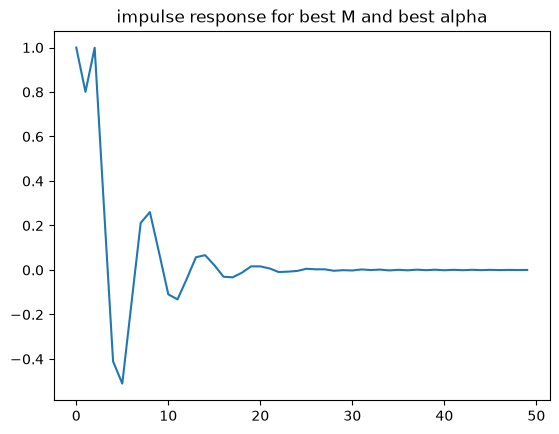

In [46]:
# Process the audio
# Find optimal M, alpha 
# For M: start with M = 20 and increase in steps of e.g. 10 until M = 150)
# For alpha consider values such as 0.01,0.1, 0.2., ... [0.01, 0.02, 0.05, 0.1, 0.2, 0.5, 0.7, 0.9, 0.95, 0.98, 0.99]
M_list = np.arange(20, 151, 10)
alpha_list = np.array([0.01, 0.02, 0.05, 0.1, 0.2, 0.5, 0.7, 0.9, 0.95, 0.98, 0.99])

N = len(x) # total length
seg2 = N - len(s) # just after final index of segment 1, first index of segment 2
seg3 = np.count_nonzero(vprime) # just after final index of segment 2, first index of segment 3
s_seg2_des = s[:seg3-seg2] # desired segment 2

# manually checking if the selected segment indices are correct
print("segment 1")
ipd.display(ipd.Audio(x[:seg2],rate=int(fs)))
print("segment 2")
ipd.display(ipd.Audio(x[seg2:seg3],rate=int(fs)))
print("segment 3")
ipd.display(ipd.Audio(x[seg3:],rate=int(fs)))

# tracking best M, alpha and an arbitrary score
best_M, best_alpha, best_score = 0, 0, np.inf

for M in M_list:
    for alpha in alpha_list:
        hEst,_ = NLMSCanceller(x[:seg2], vprime[:seg2], alpha, M) # determine the impulse response based on only segment 1
        vhat = np.convolve(hEst, vprime[seg2:seg3])[:seg3-seg2] # vhat (= the echo) for segment 2
        sEst_seg2 = x[seg2:seg3] - vhat # subtract the echo from the microphone signal
        score = np.sum(np.abs(sEst_seg2-s_seg2_des)) # updating arbitrary score
        if score < best_score:
            best_M, best_alpha, best_score = M, alpha, score # conditionally updating the best M, alpha and score

# recalculating everything for only the best variables
hEst,sEst_seg1 = NLMSCanceller(x[:seg2], vprime[:seg2], best_alpha, best_M)
vhat = np.convolve(hEst, vprime[seg2:seg3])[:seg3-seg2]
sEst_seg2 = x[seg2:seg3] - vhat
sEst = np.append(np.zeros(seg2), np.append(sEst_seg2, x[seg3:]))

# plotting relevant information for the best case
print("best M = %d, best alpha = %.2f" %(best_M, best_alpha))
plt.figure()
plt.plot(hEst)
plt.title("impulse response for best M and best alpha")
plt.show()
ipd.display(ipd.Audio(sEst,rate=int(fs)))

In [44]:
# Generate best output
bestAlpha = 0.2
bestM = 50

hEst, sEst = NLMSCanceller(x, vprime, bestAlpha, bestM)
ipd.display(ipd.Audio(sEst,rate=int(fs)))

In [48]:
bestAlpha = 0.2
bestM = 50

N = len(x) # total length
seg2 = N - len(s) # just after final index of segment 1, first index of segment 2
seg3 = np.count_nonzero(vprime) # just after final index of segment 2, first index of segment 3

hEst,sEst_seg1 = NLMSCanceller(x[:seg2], vprime[:seg2], best_alpha, best_M)
vhat = np.convolve(hEst, vprime[seg2:seg3])[:seg3-seg2]
sEst_seg2 = x[seg2:seg3] - vhat
sEst = np.append(np.zeros(seg2), np.append(sEst_seg2, x[seg3:]))

ipd.display(ipd.Audio(sEst,rate=int(fs)))

In [49]:
# write to wavfile
sEst = sEst * 2**15
sEst = np.real(sEst.astype(np.int16))
wavf.write('./assets/audio/results/group_11_echo_output.wav',fs,sEst)

<div class="alert alert-success">

The best M and $\alpha$ found by using the code above are 50 and 0.2 respectively. 

Note that just using hEst, sEst = NLMSCanceller(x, vprime, bestAlpha, bestM) does not correspond with the rules layed out earlier (simply setting first segment to all zeros, second segment will be calculated using hEst based on only first segment and third segment will be copied from the microphone signal), but instead applies the NLMSCanceller to the entire fragment. This of course does not work nearly as well as using the rules layed out earlier because the hEst is approximated using the entire fragment (including segment where both voices are present and when only speech signal is present) rather than just the echo signal. 

For this reason, we have added an extra cell to re-calculate sEst but using the rules layed out earlier and have saved this output to './assets/audio/results/group_11_echo_output.wav'.
</div>

## Further challenges

If you want to explore this field further, there are a couple of interesting exercises you could try out for your own pleasure and the challenge of it!
1. Apply the RLS to the echo problem
2. Apply the NLMS or RLS to the case of the harmonic noise. Can we think of cancelling the harmonic noise instead of notching it?